In [1]:
%pip install folium

Note: you may need to restart the kernel to use updated packages.


# ANALISIS KUALITAS UDARA DI KOTA MALANG BERDASARKAN DATA POLUTAN, CUACA, DAN HOTSPOT MENGGUNAKAN DATA SCIENCE
Sumber Data
1. OpenAQ — data kualitas udara, khususnya PM2.5.
2. Open-Meteo — data cuaca.
3. NASA FIRMS — data hotspot.

Menentukan Pertanyaan Analisis
1. Bagaimana karakteristik data kualitas udara, cuaca, dan hotspot di Kota Malang pada periode Agustus 2026 hingga periode data terakhir?
2. Bagaimana hubungan kondisi cuaca terhadap konsentrasi PM2.5 di Kota Malang pada periode Agustus 2026 hingga periode data terakhir?
3. Bagaimana hubungan keberadaan dan intensitas hotspot terhadap konsentrasi PM2.5 di Kota Malang pada periode Agustus 2026 hingga periode data terakhir?
4. Bagaimana penerapan model machine learning untuk memprediksi konsentrasi PM2.5 berdasarkan faktor cuaca dan hotspot di Kota Malang?

# 2 — ENVIRONMENT SETUP
Tahap ini digunakan untuk mempersiapkan library yang diperlukan untuk koneksi database, pengolahan data, visualisasi, dan machine learning.

In [2]:
# ============================================================
# PHASE 2 — ENVIRONMENT SETUP
# ============================================================

# Library untuk koneksi MySQL
import mysql.connector

# Library untuk manipulasi dan pengolahan data
import pandas as pd
import numpy as np

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk visualisasi spasial
import folium

# Library untuk Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Library untuk evaluasi model regresi
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

print("Semua library berhasil di-import.")

Semua library berhasil di-import.


# 3 — DATA WRANGLING
Data Wrangling merupakan proses mengolah data mentah menjadi data yang siap digunakan untuk analisis.

# 3.1 — DATA OPENAQ
OpenAQ digunakan untuk memperoleh data kualitas udara, khususnya konsentrasi PM2.5 pada lokasi pemantauan di Kota Malang.

# 3.1.1 Gathering Data
Pertama, buat koneksi ke database MySQL.

In [3]:
# ============================================================
# 3.1.1 GATHERING DATA — OPENAQ
# ============================================================

db = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="admin",
    password="admin",
    database="airflow_malang"
)

if db.is_connected():
    print("Koneksi ke database berhasil!")
else:
    print("Koneksi ke database gagal!")

Koneksi ke database berhasil!


In [4]:
query_openaq = """
SELECT
    id,
    location_id,
    latitude,
    longitude,
    sensor_id,
    sensor_name,
    parameter,
    display_name,
    unit,
    value,
    datetime_utc,
    datetime_local,
    datetime_to_utc,
    datetime_to_local,
    created_at
FROM openaq_data
WHERE parameter = 'pm25'
  AND datetime_utc >= '2026-08-01 00:00:00'
ORDER BY datetime_utc;
"""

df_openaq = pd.read_sql(
    query_openaq,
    db
)

print("Data OpenAQ berhasil diambil.")
print("Jumlah baris :", df_openaq.shape[0])
print("Jumlah kolom :", df_openaq.shape[1])

Data OpenAQ berhasil diambil.
Jumlah baris : 1565
Jumlah kolom : 15


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20688\948790893.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_openaq = pd.read_sql(


# 3.1.2 Assessing Data OpenAQ

In [5]:
df_openaq.head()

,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,display_name,unit,value,datetime_utc,datetime_local,datetime_to_utc,datetime_to_local,created_at
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,75.3,2026-08-01 00:00:00,2026-08-01 00:00:00,2026-08-01 01:00:00,2026-08-01 01:00:00,2026-10-06 07:38:44
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,56.9,2026-08-01 01:00:00,2026-08-01 01:00:00,2026-08-01 02:00:00,2026-08-01 02:00:00,2026-10-06 07:38:44
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,67.6,2026-08-01 02:00:00,2026-08-01 02:00:00,2026-08-01 03:00:00,2026-08-01 03:00:00,2026-10-06 07:38:44
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,61.4,2026-08-01 03:00:00,2026-08-01 03:00:00,2026-08-01 04:00:00,2026-08-01 04:00:00,2026-10-06 07:38:44
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,43.3,2026-08-01 04:00:00,2026-08-01 04:00:00,2026-08-01 05:00:00,2026-08-01 05:00:00,2026-10-06 07:38:44


In [6]:
df_openaq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 1565 non-null   int64         
 1   location_id        1565 non-null   object        
 2   latitude           1565 non-null   float64       
 3   longitude          1565 non-null   float64       
 4   sensor_id          1565 non-null   int64         
 5   sensor_name        1565 non-null   object        
 6   parameter          1565 non-null   object        
 7   display_name       1565 non-null   object        
 8   unit               1565 non-null   object        
 9   value              1565 non-null   float64       
 10  datetime_utc       1565 non-null   datetime64[ns]
 11  datetime_local     1565 non-null   datetime64[ns]
 12  datetime_to_utc    1565 non-null   datetime64[ns]
 13  datetime_to_local  1565 non-null   datetime64[ns]
 14  created_

In [7]:
df_openaq.describe()

,id,latitude,longitude,sensor_id,value,datetime_utc,datetime_local,datetime_to_utc,datetime_to_local,created_at
count,1565.000000,1.565000e+03,1.565000e+03,1565.0,1565.000000,1565,1565,1565,1565,1565
mean,783.065176,-7.918509e+00,1.126513e+02,14739443.0,45.150351,2026-09-03 08:06:21.853035008,2026-09-03 08:06:21.853035008,2026-09-03 09:06:21.853035008,2026-09-03 09:06:21.853035008,2026-10-06 07:42:10.683705856
min,1.000000,-7.918509e+00,1.126513e+02,14739443.0,1.200000,2026-08-01 00:00:00,2026-08-01 00:00:00,2026-08-01 01:00:00,2026-08-01 01:00:00,2026-10-06 07:38:44
25%,392.000000,-7.918509e+00,1.126513e+02,14739443.0,30.800000,2026-08-17 18:00:00,2026-08-17 18:00:00,2026-08-17 19:00:00,2026-08-17 19:00:00,2026-10-06 07:38:45
50%,783.000000,-7.918509e+00,1.126513e+02,14739443.0,41.800000,2026-09-03 02:00:00,2026-09-03 02:00:00,2026-09-03 03:00:00,2026-09-03 03:00:00,2026-10-06 07:38:45
75%,1174.000000,-7.918509e+00,1.126513e+02,14739443.0,53.500000,2026-09-20 02:00:00,2026-09-20 02:00:00,2026-09-20 03:00:00,2026-09-20 03:00:00,2026-10-06 07:38:45
max,1579.000000,-7.918509e+00,1.126513e+02,14739443.0,203.600000,2026-10-06 09:00:00,2026-10-06 09:00:00,2026-10-06 10:00:00,2026-10-06 10:00:00,2026-10-06 19:00:07
std,452.033829,1.776925e-15,1.421540e-14,0.0,22.979737,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Missing value:")
print(df_openaq.isnull().sum())

Missing value:
id                   0
location_id          0
latitude             0
longitude            0
sensor_id            0
sensor_name          0
parameter            0
display_name         0
unit                 0
value                0
datetime_utc         0
datetime_local       0
datetime_to_utc      0
datetime_to_local    0
created_at           0
dtype: int64


In [9]:
print(
    "Jumlah data duplikat:",
    df_openaq.duplicated().sum()
)

Jumlah data duplikat: 0


# 3.1.3 Cleaning Data OpenAQ

In [10]:
# Mengubah format waktu
df_openaq["datetime_utc"] = pd.to_datetime(
    df_openaq["datetime_utc"],
    errors="coerce",
    utc=True
)

df_openaq["datetime_local"] = pd.to_datetime(
    df_openaq["datetime_local"],
    errors="coerce"
)

# Menghapus data PM2.5 yang kosong
df_openaq = df_openaq.dropna(
    subset=["value"]
)

# Menghapus data duplikat
df_openaq = df_openaq.drop_duplicates()

# Membuat kolom tanggal
df_openaq["tanggal"] = (
    df_openaq["datetime_local"].dt.date
)

print("Cleaning OpenAQ selesai.")

Cleaning OpenAQ selesai.


In [11]:
# ============================================================
# ASSESSING ULANG SETELAH CLEANING
# ============================================================

print("=" * 60)
print("HASIL ASSESSING ULANG — OPENAQ")
print("=" * 60)

print("\n1. Jumlah baris dan kolom:")
print(df_openaq.shape)

print("\n2. Missing value:")
print(df_openaq.isnull().sum())

print("\n3. Jumlah duplikat:")
print(df_openaq.duplicated().sum())

print("\n4. Statistik deskriptif:")
print(df_openaq.describe())

print("\n5. Rentang tanggal:")
print("Awal  :", df_openaq["tanggal"].min())
print("Akhir :", df_openaq["tanggal"].max())

print("\n6. Data setelah cleaning:")
display(df_openaq.head())

HASIL ASSESSING ULANG — OPENAQ

1. Jumlah baris dan kolom:
(1565, 16)

2. Missing value:
id                   0
location_id          0
latitude             0
longitude            0
sensor_id            0
sensor_name          0
parameter            0
display_name         0
unit                 0
value                0
datetime_utc         0
datetime_local       0
datetime_to_utc      0
datetime_to_local    0
created_at           0
tanggal              0
dtype: int64

3. Jumlah duplikat:
0

4. Statistik deskriptif:
                id      latitude     longitude   sensor_id        value  \
count  1565.000000  1.565000e+03  1.565000e+03      1565.0  1565.000000   
mean    783.065176 -7.918509e+00  1.126513e+02  14739443.0    45.150351   
min       1.000000 -7.918509e+00  1.126513e+02  14739443.0     1.200000   
25%     392.000000 -7.918509e+00  1.126513e+02  14739443.0    30.800000   
50%     783.000000 -7.918509e+00  1.126513e+02  14739443.0    41.800000   
75%    1174.000000 -7.918509e+0

,id,location_id,latitude,longitude,sensor_id,sensor_name,parameter,display_name,unit,value,datetime_utc,datetime_local,datetime_to_utc,datetime_to_local,created_at,tanggal
0,1,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,75.3,2026-08-01 00:00:00+00:00,2026-08-01 00:00:00,2026-08-01 01:00:00,2026-08-01 01:00:00,2026-10-06 07:38:44,2026-08-01
1,2,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,56.9,2026-08-01 01:00:00+00:00,2026-08-01 01:00:00,2026-08-01 02:00:00,2026-08-01 02:00:00,2026-10-06 07:38:44,2026-08-01
2,3,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,67.6,2026-08-01 02:00:00+00:00,2026-08-01 02:00:00,2026-08-01 03:00:00,2026-08-01 03:00:00,2026-10-06 07:38:44,2026-08-01
3,4,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,61.4,2026-08-01 03:00:00+00:00,2026-08-01 03:00:00,2026-08-01 04:00:00,2026-08-01 04:00:00,2026-10-06 07:38:44,2026-08-01
4,5,6144741,-7.918509,112.651344,14739443,pm25 µg/m³,pm25,PM2.5,µg/m³,43.3,2026-08-01 04:00:00+00:00,2026-08-01 04:00:00,2026-08-01 05:00:00,2026-08-01 05:00:00,2026-10-06 07:38:44,2026-08-01


# 3.1.4 Transformation — OpenAQ

In [12]:
# ============================================================
# 4.1.4 TRANSFORMATION - OPENAQ
# ============================================================

# Mengubah kolom waktu ke format datetime
df_openaq["datetime_utc"] = pd.to_datetime(
    df_openaq["datetime_utc"],
    errors="coerce",
    utc=True
)

df_openaq["datetime_local"] = pd.to_datetime(
    df_openaq["datetime_local"],
    errors="coerce"
)

# Memastikan nilai PM2.5 bertipe numerik
df_openaq["value"] = pd.to_numeric(
    df_openaq["value"],
    errors="coerce"
)

# Membuat kolom tanggal untuk proses agregasi
df_openaq["tanggal"] = df_openaq["datetime_local"].dt.date

# Menampilkan hasil transformation
print("Hasil Transformation OpenAQ:")
display(
    df_openaq[
        [
            "datetime_utc",
            "datetime_local",
            "tanggal",
            "value",
            "unit",
            "parameter"
        ]
    ].head()
)

# Menampilkan tipe data
print("\nTipe data setelah transformation:")
print(
    df_openaq[
        [
            "datetime_utc",
            "datetime_local",
            "tanggal",
            "value"
        ]
    ].dtypes
)

Hasil Transformation OpenAQ:


,datetime_utc,datetime_local,tanggal,value,unit,parameter
0,2026-08-01 00:00:00+00:00,2026-08-01 00:00:00,2026-08-01,75.3,µg/m³,pm25
1,2026-08-01 01:00:00+00:00,2026-08-01 01:00:00,2026-08-01,56.9,µg/m³,pm25
2,2026-08-01 02:00:00+00:00,2026-08-01 02:00:00,2026-08-01,67.6,µg/m³,pm25
3,2026-08-01 03:00:00+00:00,2026-08-01 03:00:00,2026-08-01,61.4,µg/m³,pm25
4,2026-08-01 04:00:00+00:00,2026-08-01 04:00:00,2026-08-01,43.3,µg/m³,pm25



Tipe data setelah transformation:
datetime_utc      datetime64[ns, UTC]
datetime_local         datetime64[ns]
tanggal                        object
value                         float64
dtype: object


# 3.1.5 Data Aggregation — OpenAQ
Pada tahap ini, data PM2.5 yang sebelumnya masih berupa pengukuran per waktu diagregasi menjadi data harian. Nilai yang digunakan adalah rata-rata, minimum, maksimum, dan standar deviasi PM2.5 setiap tanggal.

In [13]:
# ============================================================
# 4.1.5 DATA AGGREGATION - OPENAQ
# ============================================================

print("=== DATA AGGREGATION OPENAQ ===")

openaq_daily = (
    df_openaq
    .groupby("tanggal")["value"]
    .agg(
        PM2_5="mean",
        PM2_5_min="min",
        PM2_5_max="max",
        PM2_5_std="std"
    )
    .reset_index()
)

# Pembulatan nilai
openaq_daily[
    ["PM2_5", "PM2_5_min", "PM2_5_max", "PM2_5_std"]
] = openaq_daily[
    ["PM2_5", "PM2_5_min", "PM2_5_max", "PM2_5_std"]
].round(2)

print("Jumlah data harian:", len(openaq_daily))

display(openaq_daily.head(10))

=== DATA AGGREGATION OPENAQ ===
Jumlah data harian: 67


,tanggal,PM2_5,PM2_5_min,PM2_5_max,PM2_5_std
0,2026-08-01,48.97,34.3,86.7,14.05
1,2026-08-02,22.72,3.5,78.1,16.07
2,2026-08-03,41.89,22.9,74.9,15.78
3,2026-08-04,53.07,35.4,88.0,16.83
4,2026-08-05,39.93,14.3,66.3,11.89
5,2026-08-06,54.59,23.7,154.2,30.94
6,2026-08-07,57.23,36.2,98.0,17.71
7,2026-08-08,31.96,8.7,67.0,14.88
8,2026-08-09,34.78,18.6,52.7,10.56
9,2026-08-10,48.68,31.0,67.5,12.46


# 3.1.6 Feature Engineering — OpenAQ
ada tahap ini kita membuat fitur yang lebih informatif dari hasil agregasi PM2.5 harian. Untuk OpenAQ, PM2.5 rata-rata (PM2_5) tetap menjadi target utama, sedangkan fitur tambahan dapat digunakan untuk menggambarkan variasi konsentrasi dalam sehari.

In [14]:
# ============================================================
# FEATURE ENGINEERING - OPENAQ
# ============================================================

print("=== FEATURE ENGINEERING OPENAQ ===")

openaq_feature = openaq_daily[
    ["tanggal", "PM2_5"]
].copy()

display(openaq_feature.head(10))

=== FEATURE ENGINEERING OPENAQ ===


,tanggal,PM2_5
0,2026-08-01,48.97
1,2026-08-02,22.72
2,2026-08-03,41.89
3,2026-08-04,53.07
4,2026-08-05,39.93
5,2026-08-06,54.59
6,2026-08-07,57.23
7,2026-08-08,31.96
8,2026-08-09,34.78
9,2026-08-10,48.68


In [15]:
print("=== FITUR AKHIR OPENAQ ===")

print("Jumlah baris :", len(openaq_feature))
print("Jumlah kolom :", len(openaq_feature.columns))

display(openaq_feature.describe())

=== FITUR AKHIR OPENAQ ===
Jumlah baris : 67
Jumlah kolom : 2


,PM2_5
count,67.000000
mean,44.935970
std,12.614164
min,15.170000
25%,36.430000
50%,45.450000
75%,54.825000
max,74.710000


# 3.2 Open-Meteo
Data Open-Meteo digunakan untuk memperoleh informasi kondisi cuaca di Kota Malang, meliputi suhu, kelembapan, curah hujan, kecepatan angin, arah angin, tekanan udara, dan tutupan awan.

# 3.2.1 Gathering — Open-Meteo
Data cuaca diperoleh dari tabel openmeteo_data pada database MySQL yang telah diisi melalui proses ETL dari API Open-Meteo. Data yang digunakan memiliki periode mulai Agustus 2026 hingga data terakhir yang tersedia.

In [16]:
# ============================================================
# GATHERING - OPEN-METEO
# ============================================================

openmeteo = pd.read_sql("""
    SELECT *
    FROM openmeteo_data
""", db)

print("=== DATA OPEN-METEO ===")
print(f"Jumlah baris : {openmeteo.shape[0]:,}")
print(f"Jumlah kolom : {openmeteo.shape[1]:,}")

display(openmeteo.head(10))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20688\603300133.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  openmeteo = pd.read_sql("""


=== DATA OPEN-METEO ===
Jumlah baris : 1,608
Jumlah kolom : 14


,id,location_id,datetime_utc,datetime_local,latitude,longitude,temperature,humidity,precipitation,wind_speed,wind_direction,pressure,cloud_cover,created_at
0,1,malang,2026-08-01 00:00:00,2026-08-01 00:00:00,-7.918509,112.651344,20.2,81.0,0.0,1.4,293.0,960.7,16.0,2026-10-06 07:39:57
1,2,malang,2026-08-01 01:00:00,2026-08-01 01:00:00,-7.918509,112.651344,22.8,69.0,0.0,1.3,90.0,961.1,44.0,2026-10-06 07:39:57
2,3,malang,2026-08-01 02:00:00,2026-08-01 02:00:00,-7.918509,112.651344,25.0,63.0,0.0,4.3,123.0,961.1,91.0,2026-10-06 07:39:57
3,4,malang,2026-08-01 03:00:00,2026-08-01 03:00:00,-7.918509,112.651344,26.3,61.0,0.0,6.7,109.0,960.6,70.0,2026-10-06 07:39:57
4,5,malang,2026-08-01 04:00:00,2026-08-01 04:00:00,-7.918509,112.651344,27.5,58.0,0.0,9.6,95.0,959.8,81.0,2026-10-06 07:39:57
5,6,malang,2026-08-01 05:00:00,2026-08-01 05:00:00,-7.918509,112.651344,28.3,53.0,0.0,11.4,84.0,959.5,90.0,2026-10-06 07:39:57
6,7,malang,2026-08-01 06:00:00,2026-08-01 06:00:00,-7.918509,112.651344,28.8,48.0,0.0,10.0,81.0,958.8,64.0,2026-10-06 07:39:57
7,8,malang,2026-08-01 07:00:00,2026-08-01 07:00:00,-7.918509,112.651344,27.9,52.0,0.0,12.6,61.0,957.7,32.0,2026-10-06 07:39:57
8,9,malang,2026-08-01 08:00:00,2026-08-01 08:00:00,-7.918509,112.651344,27.9,54.0,0.0,11.9,56.0,957.3,22.0,2026-10-06 07:39:57
9,10,malang,2026-08-01 09:00:00,2026-08-01 09:00:00,-7.918509,112.651344,26.7,60.0,0.0,11.3,56.0,957.4,19.0,2026-10-06 07:39:57


# 3.2.2 Assessing — Open-Meteo
Tahap Assessing dilakukan untuk memahami kondisi awal data Open-Meteo sebelum dilakukan pembersihan. Pemeriksaan meliputi jumlah data, struktur data, sampel data, periode data, serta statistik deskriptif variabel cuaca.

In [17]:
# ============================================================
#  ASSESSING - OPEN-METEO
# ============================================================

print("=== HEAD DATA ===")
display(openmeteo.head(10))

print("\n=== INFO DATA ===")
openmeteo.info()

print("\n=== DESCRIBE DATA ===")
display(openmeteo.describe())

print("\n=== MISSING VALUES ===")
print(openmeteo.isnull().sum())

print("\n=== DUPLICATE DATA ===")
print("Jumlah data duplikat:", openmeteo.duplicated().sum())

=== HEAD DATA ===


,id,location_id,datetime_utc,datetime_local,latitude,longitude,temperature,humidity,precipitation,wind_speed,wind_direction,pressure,cloud_cover,created_at
0,1,malang,2026-08-01 00:00:00,2026-08-01 00:00:00,-7.918509,112.651344,20.2,81.0,0.0,1.4,293.0,960.7,16.0,2026-10-06 07:39:57
1,2,malang,2026-08-01 01:00:00,2026-08-01 01:00:00,-7.918509,112.651344,22.8,69.0,0.0,1.3,90.0,961.1,44.0,2026-10-06 07:39:57
2,3,malang,2026-08-01 02:00:00,2026-08-01 02:00:00,-7.918509,112.651344,25.0,63.0,0.0,4.3,123.0,961.1,91.0,2026-10-06 07:39:57
3,4,malang,2026-08-01 03:00:00,2026-08-01 03:00:00,-7.918509,112.651344,26.3,61.0,0.0,6.7,109.0,960.6,70.0,2026-10-06 07:39:57
4,5,malang,2026-08-01 04:00:00,2026-08-01 04:00:00,-7.918509,112.651344,27.5,58.0,0.0,9.6,95.0,959.8,81.0,2026-10-06 07:39:57
5,6,malang,2026-08-01 05:00:00,2026-08-01 05:00:00,-7.918509,112.651344,28.3,53.0,0.0,11.4,84.0,959.5,90.0,2026-10-06 07:39:57
6,7,malang,2026-08-01 06:00:00,2026-08-01 06:00:00,-7.918509,112.651344,28.8,48.0,0.0,10.0,81.0,958.8,64.0,2026-10-06 07:39:57
7,8,malang,2026-08-01 07:00:00,2026-08-01 07:00:00,-7.918509,112.651344,27.9,52.0,0.0,12.6,61.0,957.7,32.0,2026-10-06 07:39:57
8,9,malang,2026-08-01 08:00:00,2026-08-01 08:00:00,-7.918509,112.651344,27.9,54.0,0.0,11.9,56.0,957.3,22.0,2026-10-06 07:39:57
9,10,malang,2026-08-01 09:00:00,2026-08-01 09:00:00,-7.918509,112.651344,26.7,60.0,0.0,11.3,56.0,957.4,19.0,2026-10-06 07:39:57



=== INFO DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1608 entries, 0 to 1607
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              1608 non-null   int64         
 1   location_id     1608 non-null   object        
 2   datetime_utc    1608 non-null   datetime64[ns]
 3   datetime_local  1608 non-null   datetime64[ns]
 4   latitude        1608 non-null   float64       
 5   longitude       1608 non-null   float64       
 6   temperature     1608 non-null   float64       
 7   humidity        1608 non-null   float64       
 8   precipitation   1608 non-null   float64       
 9   wind_speed      1608 non-null   float64       
 10  wind_direction  1608 non-null   float64       
 11  pressure        1608 non-null   float64       
 12  cloud_cover     1608 non-null   float64       
 13  created_at      1608 non-null   datetime64[ns]
dtypes: datetime64[ns](3), float64(9), int

,id,datetime_utc,datetime_local,latitude,longitude,temperature,humidity,precipitation,wind_speed,wind_direction,pressure,cloud_cover,created_at
count,1608.000000,1608,1608,1.608000e+03,1.608000e+03,1608.00000,1608.000000,1608.000000,1608.000000,1608.000000,1608.000000,1608.000000,1608
mean,804.858209,2026-09-03 11:30:00,2026-09-03 11:30:00,-7.918509e+00,1.126513e+02,23.24602,70.824005,0.011692,6.748756,181.355721,961.439739,42.743781,2026-10-06 07:40:15.845771264
min,1.000000,2026-08-01 00:00:00,2026-08-01 00:00:00,-7.918509e+00,1.126513e+02,15.10000,25.000000,0.000000,0.000000,1.000000,957.300000,0.000000,2026-10-06 07:39:57
25%,402.750000,2026-08-17 17:45:00,2026-08-17 17:45:00,-7.918509e+00,1.126513e+02,19.90000,52.750000,0.000000,3.300000,90.000000,960.400000,11.000000,2026-10-06 07:39:57
50%,804.500000,2026-09-03 11:30:00,2026-09-03 11:30:00,-7.918509e+00,1.126513e+02,22.30000,74.000000,0.000000,6.400000,185.500000,961.400000,35.000000,2026-10-06 07:39:58
75%,1206.250000,2026-09-20 05:15:00,2026-09-20 05:15:00,-7.918509e+00,1.126513e+02,26.70000,89.000000,0.000000,9.600000,259.000000,962.400000,74.000000,2026-10-06 07:39:58
max,1632.000000,2026-10-06 23:00:00,2026-10-06 23:00:00,-7.918509e+00,1.126513e+02,32.60000,100.000000,3.700000,21.200000,360.000000,965.700000,100.000000,2026-10-06 08:00:07
std,464.954009,NaN,NaN,1.776909e-15,1.421528e-14,3.90057,20.312971,0.109420,3.957081,97.680825,1.475279,34.511278,NaN



=== MISSING VALUES ===
id                0
location_id       0
datetime_utc      0
datetime_local    0
latitude          0
longitude         0
temperature       0
humidity          0
precipitation     0
wind_speed        0
wind_direction    0
pressure          0
cloud_cover       0
created_at        0
dtype: int64

=== DUPLICATE DATA ===
Jumlah data duplikat: 0


# 3.2.3 Cleaning — Open-Meteo
Tahap Cleaning dilakukan untuk membersihkan data Open-Meteo dari data duplikat dan missing value agar data siap digunakan pada tahap Transformation, Aggregation, dan Feature Engineering.

In [18]:
# ============================================================
#  CLEANING - OPEN-METEO
# ============================================================

print("=== CLEANING DATA OPEN-METEO ===")

# Menghapus data duplikat
openmeteo = openmeteo.drop_duplicates()

# Menghapus baris yang seluruhnya kosong
openmeteo = openmeteo.dropna(how="all")

print("Jumlah data setelah cleaning:", openmeteo.shape)

print("\nMissing values setelah cleaning:")
print(openmeteo.isnull().sum())

print("\nJumlah data duplikat setelah cleaning:")
print(openmeteo.duplicated().sum())

display(openmeteo.head(10))

=== CLEANING DATA OPEN-METEO ===
Jumlah data setelah cleaning: (1608, 14)

Missing values setelah cleaning:
id                0
location_id       0
datetime_utc      0
datetime_local    0
latitude          0
longitude         0
temperature       0
humidity          0
precipitation     0
wind_speed        0
wind_direction    0
pressure          0
cloud_cover       0
created_at        0
dtype: int64

Jumlah data duplikat setelah cleaning:
0


,id,location_id,datetime_utc,datetime_local,latitude,longitude,temperature,humidity,precipitation,wind_speed,wind_direction,pressure,cloud_cover,created_at
0,1,malang,2026-08-01 00:00:00,2026-08-01 00:00:00,-7.918509,112.651344,20.2,81.0,0.0,1.4,293.0,960.7,16.0,2026-10-06 07:39:57
1,2,malang,2026-08-01 01:00:00,2026-08-01 01:00:00,-7.918509,112.651344,22.8,69.0,0.0,1.3,90.0,961.1,44.0,2026-10-06 07:39:57
2,3,malang,2026-08-01 02:00:00,2026-08-01 02:00:00,-7.918509,112.651344,25.0,63.0,0.0,4.3,123.0,961.1,91.0,2026-10-06 07:39:57
3,4,malang,2026-08-01 03:00:00,2026-08-01 03:00:00,-7.918509,112.651344,26.3,61.0,0.0,6.7,109.0,960.6,70.0,2026-10-06 07:39:57
4,5,malang,2026-08-01 04:00:00,2026-08-01 04:00:00,-7.918509,112.651344,27.5,58.0,0.0,9.6,95.0,959.8,81.0,2026-10-06 07:39:57
5,6,malang,2026-08-01 05:00:00,2026-08-01 05:00:00,-7.918509,112.651344,28.3,53.0,0.0,11.4,84.0,959.5,90.0,2026-10-06 07:39:57
6,7,malang,2026-08-01 06:00:00,2026-08-01 06:00:00,-7.918509,112.651344,28.8,48.0,0.0,10.0,81.0,958.8,64.0,2026-10-06 07:39:57
7,8,malang,2026-08-01 07:00:00,2026-08-01 07:00:00,-7.918509,112.651344,27.9,52.0,0.0,12.6,61.0,957.7,32.0,2026-10-06 07:39:57
8,9,malang,2026-08-01 08:00:00,2026-08-01 08:00:00,-7.918509,112.651344,27.9,54.0,0.0,11.9,56.0,957.3,22.0,2026-10-06 07:39:57
9,10,malang,2026-08-01 09:00:00,2026-08-01 09:00:00,-7.918509,112.651344,26.7,60.0,0.0,11.3,56.0,957.4,19.0,2026-10-06 07:39:57


# 3.2.4 Transformation — Open-Meteo

In [19]:
# ============================================================
# TRANSFORMATION - OPEN-METEO
# ============================================================

print("=== TRANSFORMATION OPEN-METEO ===")

# Mengubah kolom waktu ke format datetime
openmeteo["datetime_utc"] = pd.to_datetime(
    openmeteo["datetime_utc"],
    errors="coerce",
    utc=True
)

openmeteo["datetime_local"] = pd.to_datetime(
    openmeteo["datetime_local"],
    errors="coerce"
)

# Mengubah kolom cuaca menjadi numerik
kolom_numerik = [
    "temperature",
    "humidity",
    "precipitation",
    "wind_speed",
    "wind_direction",
    "pressure",
    "cloud_cover"
]

for kolom in kolom_numerik:
    openmeteo[kolom] = pd.to_numeric(
        openmeteo[kolom],
        errors="coerce"
    )

# Membuat kolom tanggal untuk agregasi harian
openmeteo["tanggal"] = (
    openmeteo["datetime_local"].dt.date
)

print("Hasil Transformation Open-Meteo:")
display(openmeteo.head(10))

print("\nTipe data setelah transformation:")
print(openmeteo.dtypes)

=== TRANSFORMATION OPEN-METEO ===
Hasil Transformation Open-Meteo:


,id,location_id,datetime_utc,datetime_local,latitude,longitude,temperature,humidity,precipitation,wind_speed,wind_direction,pressure,cloud_cover,created_at,tanggal
0,1,malang,2026-08-01 00:00:00+00:00,2026-08-01 00:00:00,-7.918509,112.651344,20.2,81.0,0.0,1.4,293.0,960.7,16.0,2026-10-06 07:39:57,2026-08-01
1,2,malang,2026-08-01 01:00:00+00:00,2026-08-01 01:00:00,-7.918509,112.651344,22.8,69.0,0.0,1.3,90.0,961.1,44.0,2026-10-06 07:39:57,2026-08-01
2,3,malang,2026-08-01 02:00:00+00:00,2026-08-01 02:00:00,-7.918509,112.651344,25.0,63.0,0.0,4.3,123.0,961.1,91.0,2026-10-06 07:39:57,2026-08-01
3,4,malang,2026-08-01 03:00:00+00:00,2026-08-01 03:00:00,-7.918509,112.651344,26.3,61.0,0.0,6.7,109.0,960.6,70.0,2026-10-06 07:39:57,2026-08-01
4,5,malang,2026-08-01 04:00:00+00:00,2026-08-01 04:00:00,-7.918509,112.651344,27.5,58.0,0.0,9.6,95.0,959.8,81.0,2026-10-06 07:39:57,2026-08-01
5,6,malang,2026-08-01 05:00:00+00:00,2026-08-01 05:00:00,-7.918509,112.651344,28.3,53.0,0.0,11.4,84.0,959.5,90.0,2026-10-06 07:39:57,2026-08-01
6,7,malang,2026-08-01 06:00:00+00:00,2026-08-01 06:00:00,-7.918509,112.651344,28.8,48.0,0.0,10.0,81.0,958.8,64.0,2026-10-06 07:39:57,2026-08-01
7,8,malang,2026-08-01 07:00:00+00:00,2026-08-01 07:00:00,-7.918509,112.651344,27.9,52.0,0.0,12.6,61.0,957.7,32.0,2026-10-06 07:39:57,2026-08-01
8,9,malang,2026-08-01 08:00:00+00:00,2026-08-01 08:00:00,-7.918509,112.651344,27.9,54.0,0.0,11.9,56.0,957.3,22.0,2026-10-06 07:39:57,2026-08-01
9,10,malang,2026-08-01 09:00:00+00:00,2026-08-01 09:00:00,-7.918509,112.651344,26.7,60.0,0.0,11.3,56.0,957.4,19.0,2026-10-06 07:39:57,2026-08-01



Tipe data setelah transformation:
id                              int64
location_id                    object
datetime_utc      datetime64[ns, UTC]
datetime_local         datetime64[ns]
latitude                      float64
longitude                     float64
temperature                   float64
humidity                      float64
precipitation                 float64
wind_speed                    float64
wind_direction                float64
pressure                      float64
cloud_cover                   float64
created_at             datetime64[ns]
tanggal                        object
dtype: object


# 3.2.5 Data Aggregation — Open-Meteo
Tujuannya adalah mengubah data cuaca yang awalnya per jam menjadi data per hari, supaya nanti bisa digabungkan dengan data PM2.5 dan hotspot berdasarkan tanggal.

In [20]:
# ============================================================
# DATA AGGREGATION - OPEN-METEO
# ============================================================

print("=== DATA AGGREGATION OPEN-METEO ===")

openmeteo_daily = (
    openmeteo
    .groupby("tanggal")
    .agg(
        temperature_mean=("temperature", "mean"),
        temperature_max=("temperature", "max"),
        temperature_min=("temperature", "min"),
        humidity_mean=("humidity", "mean"),
        precipitation_sum=("precipitation", "sum"),
        pressure_mean=("pressure", "mean"),
        wind_speed_mean=("wind_speed", "mean"),
        wind_direction_mean=("wind_direction", "mean"),
        cloud_cover_mean=("cloud_cover", "mean")
    )
    .reset_index()
)

# Membulatkan nilai numerik
kolom_bulat = [
    "temperature_mean",
    "temperature_max",
    "temperature_min",
    "humidity_mean",
    "precipitation_sum",
    "pressure_mean",
    "wind_speed_mean",
    "wind_direction_mean",
    "cloud_cover_mean"
]

openmeteo_daily[kolom_bulat] = (
    openmeteo_daily[kolom_bulat].round(2)
)

print("Jumlah data harian:", len(openmeteo_daily))

display(openmeteo_daily.head(10))

=== DATA AGGREGATION OPEN-METEO ===
Jumlah data harian: 67


,tanggal,temperature_mean,temperature_max,temperature_min,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean
0,2026-08-01,23.03,28.8,19.0,73.42,0.0,959.12,6.73,188.12,47.04
1,2026-08-02,23.61,28.6,19.4,72.33,0.0,959.35,10.60,165.71,24.67
2,2026-08-03,23.18,28.2,18.9,76.12,0.0,959.84,7.42,157.00,32.42
3,2026-08-04,22.81,28.2,18.0,78.58,0.0,960.09,4.84,156.58,30.04
4,2026-08-05,22.30,27.8,17.3,67.92,0.0,959.63,5.63,171.79,49.50
5,2026-08-06,22.55,27.6,18.0,70.42,0.0,960.05,4.80,200.75,27.88
6,2026-08-07,22.30,28.4,17.8,68.38,0.0,960.33,6.49,193.58,20.67
7,2026-08-08,22.25,28.7,18.3,74.12,0.0,961.52,8.43,198.00,43.46
8,2026-08-09,21.54,27.7,17.0,78.33,0.0,960.08,6.38,184.54,61.12
9,2026-08-10,21.85,27.8,17.9,77.83,0.0,959.80,6.78,180.33,47.62


# 3.2.6 Feature Engineering — Open-Meteo.
Pada tahap ini kita memilih fitur cuaca yang sudah dihasilkan pada agregasi harian dan membuat openmeteo_feature sebagai dataset yang siap digunakan pada tahap integrasi nanti.

In [21]:
# ============================================================
# FEATURE ENGINEERING - OPEN-METEO
# ============================================================

print("=== FEATURE ENGINEERING OPEN-METEO ===")

openmeteo_feature = openmeteo_daily[
    [
        "tanggal",
        "temperature_mean",
        "humidity_mean",
        "precipitation_sum",
        "pressure_mean",
        "wind_speed_mean",
        "wind_direction_mean",
        "cloud_cover_mean"
    ]
].copy()

print("Jumlah data feature Open-Meteo:", openmeteo_feature.shape)

display(openmeteo_feature.head(10))

=== FEATURE ENGINEERING OPEN-METEO ===
Jumlah data feature Open-Meteo: (67, 8)


,tanggal,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean
0,2026-08-01,23.03,73.42,0.0,959.12,6.73,188.12,47.04
1,2026-08-02,23.61,72.33,0.0,959.35,10.60,165.71,24.67
2,2026-08-03,23.18,76.12,0.0,959.84,7.42,157.00,32.42
3,2026-08-04,22.81,78.58,0.0,960.09,4.84,156.58,30.04
4,2026-08-05,22.30,67.92,0.0,959.63,5.63,171.79,49.50
5,2026-08-06,22.55,70.42,0.0,960.05,4.80,200.75,27.88
6,2026-08-07,22.30,68.38,0.0,960.33,6.49,193.58,20.67
7,2026-08-08,22.25,74.12,0.0,961.52,8.43,198.00,43.46
8,2026-08-09,21.54,78.33,0.0,960.08,6.38,184.54,61.12
9,2026-08-10,21.85,77.83,0.0,959.80,6.78,180.33,47.62


# 3.3 DATA FIRMS
Data NASA FIRMS (Fire Information for Resource Management System) digunakan untuk memperoleh informasi hotspot di wilayah Kota Malang. Data yang digunakan meliputi lokasi hotspot, waktu terdeteksi, satelit, tingkat kepercayaan deteksi, dan Fire Radiative Power (FRP).

# 3.3.1 Gathering — NASA FIRMS
Pada tahap Gathering, kita mengambil data hotspot yang sudah tersimpan di tabel firms_data pada database. Karena periode penelitian kita mulai 1 Agustus 2026, data yang digunakan juga dibatasi mulai tanggal tersebut.

In [22]:
# ============================================================
#  GATHERING - NASA FIRMS
# ============================================================

print("=== DATA NASA FIRMS ===")

firms = pd.read_sql("""
    SELECT *
    FROM firms_data
    WHERE acq_date >= '2026-08-01'
    ORDER BY acq_date, acq_time;
""", db)

print(f"Jumlah baris : {firms.shape[0]:,}")
print(f"Jumlah kolom : {firms.shape[1]:,}")

display(firms.head(10))

=== DATA NASA FIRMS ===


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20688\1120148212.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  firms = pd.read_sql("""


Jumlah baris : 271
Jumlah kolom : 14


,id,location_id,latitude,longitude,acq_date,acq_time,datetime_utc,datetime_local,satellite,instrument,confidence,frp,daynight,created_at
0,35,MALANG,-7.81635,112.69624,2026-08-07,0550,2026-08-07 05:50:00,2026-08-07 12:50:00,N20,VIIRS,n,2.53,D,2026-10-06 07:32:30
1,36,MALANG,-7.72478,112.74537,2026-08-08,1815,2026-08-08 18:15:00,2026-08-09 01:15:00,N20,VIIRS,n,0.79,N,2026-10-06 07:32:30
2,37,MALANG,-7.75031,112.84715,2026-08-10,1824,2026-08-10 18:24:00,2026-08-11 01:24:00,N21,VIIRS,n,0.73,N,2026-10-06 07:32:30
3,38,MALANG,-7.74622,112.81309,2026-08-13,1728,2026-08-13 17:28:00,2026-08-14 00:28:00,N21,VIIRS,n,0.76,N,2026-10-06 07:32:30
4,39,MALANG,-7.85837,112.69189,2026-08-17,0603,2026-08-17 06:03:00,2026-08-17 13:03:00,N20,VIIRS,n,4.46,D,2026-10-06 07:32:30
5,40,MALANG,-7.83167,112.73396,2026-08-17,0603,2026-08-17 06:03:00,2026-08-17 13:03:00,N20,VIIRS,n,1.81,D,2026-10-06 07:32:30
6,41,MALANG,-7.94791,112.68982,2026-08-18,0544,2026-08-18 05:44:00,2026-08-18 12:44:00,N20,VIIRS,l,2.52,D,2026-10-06 07:32:30
7,42,MALANG,-7.75200,112.58708,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,5.40,D,2026-10-06 07:32:30
8,43,MALANG,-7.75163,112.58986,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,5.40,D,2026-10-06 07:32:30
9,44,MALANG,-7.74726,112.57995,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,28.84,D,2026-10-06 07:32:30


# 3.3.2 Assessing — NASA FIRMS
Tahap Assessing digunakan untuk mengecek kondisi awal data FIRMS sebelum dilakukan pembersihan. Kita melihat struktur data, statistik, nilai kosong, dan data duplikat.

In [23]:
# ============================================================
# ASSESSING - NASA FIRMS
# ============================================================

print("=== ASSESSING DATA NASA FIRMS ===")

print("\n=== HEAD DATA ===")
display(firms.head(10))

print("\n=== INFO DATA ===")
firms.info()

print("\n=== DESCRIBE DATA ===")
display(firms.describe())

print("\n=== MISSING VALUES ===")
print(firms.isnull().sum())

print("\n=== DUPLICATE DATA ===")
print("Jumlah data duplikat:", firms.duplicated().sum())

=== ASSESSING DATA NASA FIRMS ===

=== HEAD DATA ===


,id,location_id,latitude,longitude,acq_date,acq_time,datetime_utc,datetime_local,satellite,instrument,confidence,frp,daynight,created_at
0,35,MALANG,-7.81635,112.69624,2026-08-07,0550,2026-08-07 05:50:00,2026-08-07 12:50:00,N20,VIIRS,n,2.53,D,2026-10-06 07:32:30
1,36,MALANG,-7.72478,112.74537,2026-08-08,1815,2026-08-08 18:15:00,2026-08-09 01:15:00,N20,VIIRS,n,0.79,N,2026-10-06 07:32:30
2,37,MALANG,-7.75031,112.84715,2026-08-10,1824,2026-08-10 18:24:00,2026-08-11 01:24:00,N21,VIIRS,n,0.73,N,2026-10-06 07:32:30
3,38,MALANG,-7.74622,112.81309,2026-08-13,1728,2026-08-13 17:28:00,2026-08-14 00:28:00,N21,VIIRS,n,0.76,N,2026-10-06 07:32:30
4,39,MALANG,-7.85837,112.69189,2026-08-17,0603,2026-08-17 06:03:00,2026-08-17 13:03:00,N20,VIIRS,n,4.46,D,2026-10-06 07:32:30
5,40,MALANG,-7.83167,112.73396,2026-08-17,0603,2026-08-17 06:03:00,2026-08-17 13:03:00,N20,VIIRS,n,1.81,D,2026-10-06 07:32:30
6,41,MALANG,-7.94791,112.68982,2026-08-18,0544,2026-08-18 05:44:00,2026-08-18 12:44:00,N20,VIIRS,l,2.52,D,2026-10-06 07:32:30
7,42,MALANG,-7.75200,112.58708,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,5.40,D,2026-10-06 07:32:30
8,43,MALANG,-7.75163,112.58986,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,5.40,D,2026-10-06 07:32:30
9,44,MALANG,-7.74726,112.57995,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,28.84,D,2026-10-06 07:32:30



=== INFO DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271 entries, 0 to 270
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              271 non-null    int64         
 1   location_id     271 non-null    object        
 2   latitude        271 non-null    float64       
 3   longitude       271 non-null    float64       
 4   acq_date        271 non-null    object        
 5   acq_time        271 non-null    object        
 6   datetime_utc    271 non-null    datetime64[ns]
 7   datetime_local  271 non-null    datetime64[ns]
 8   satellite       271 non-null    object        
 9   instrument      271 non-null    object        
 10  confidence      271 non-null    object        
 11  frp             271 non-null    float64       
 12  daynight        271 non-null    object        
 13  created_at      271 non-null    datetime64[ns]
dtypes: datetime64[ns](3), float64(3), int64

,id,latitude,longitude,datetime_utc,datetime_local,frp,created_at
count,271.000000,271.000000,271.000000,271,271,271.000000,271
mean,170.354244,-7.893861,112.542693,2026-09-11 23:50:13.948339712,2026-09-12 06:50:13.948339456,7.899557,2026-10-06 07:46:33.940959744
min,35.000000,-8.141930,112.450590,2026-08-07 05:50:00,2026-08-07 12:50:00,0.270000,2026-10-06 07:32:30
25%,102.500000,-7.953705,112.468110,2026-09-05 06:48:00,2026-09-05 13:48:00,1.605000,2026-10-06 07:32:30
50%,170.000000,-7.937550,112.481930,2026-09-13 18:41:00,2026-09-14 01:41:00,3.670000,2026-10-06 07:32:30
75%,237.500000,-7.771650,112.596615,2026-09-16 17:45:00,2026-09-17 00:45:00,9.190000,2026-10-06 07:32:30
max,313.000000,-7.707820,112.849170,2026-10-06 06:10:00,2026-10-06 13:10:00,69.930000,2026-10-06 17:46:58
std,78.977681,0.097755,0.108317,NaN,NaN,10.247327,NaN



=== MISSING VALUES ===
id                0
location_id       0
latitude          0
longitude         0
acq_date          0
acq_time          0
datetime_utc      0
datetime_local    0
satellite         0
instrument        0
confidence        0
frp               0
daynight          0
created_at        0
dtype: int64

=== DUPLICATE DATA ===
Jumlah data duplikat: 0


# 3.3.3 CLEANING - NASA FIRMS

In [24]:
# ============================================================
# 3.3.3 CLEANING - NASA FIRMS
# ============================================================

print("=== CLEANING DATA NASA FIRMS ===")

# Missing values sebelum cleaning
print("Missing values sebelum cleaning:")
print(firms.isnull().sum())

# Menghapus baris yang seluruhnya kosong
firms = firms.dropna(how="all")

# Menghapus data duplikat
firms = firms.drop_duplicates()

# Cek kembali setelah cleaning
print("\nMissing values setelah cleaning:")
print(firms.isnull().sum())

print("\nJumlah data duplikat setelah cleaning:")
print(firms.duplicated().sum())

print("\nJumlah data setelah cleaning:")
print(firms.shape)

display(firms.head(10))

=== CLEANING DATA NASA FIRMS ===
Missing values sebelum cleaning:
id                0
location_id       0
latitude          0
longitude         0
acq_date          0
acq_time          0
datetime_utc      0
datetime_local    0
satellite         0
instrument        0
confidence        0
frp               0
daynight          0
created_at        0
dtype: int64

Missing values setelah cleaning:
id                0
location_id       0
latitude          0
longitude         0
acq_date          0
acq_time          0
datetime_utc      0
datetime_local    0
satellite         0
instrument        0
confidence        0
frp               0
daynight          0
created_at        0
dtype: int64

Jumlah data duplikat setelah cleaning:
0

Jumlah data setelah cleaning:
(271, 14)


,id,location_id,latitude,longitude,acq_date,acq_time,datetime_utc,datetime_local,satellite,instrument,confidence,frp,daynight,created_at
0,35,MALANG,-7.81635,112.69624,2026-08-07,0550,2026-08-07 05:50:00,2026-08-07 12:50:00,N20,VIIRS,n,2.53,D,2026-10-06 07:32:30
1,36,MALANG,-7.72478,112.74537,2026-08-08,1815,2026-08-08 18:15:00,2026-08-09 01:15:00,N20,VIIRS,n,0.79,N,2026-10-06 07:32:30
2,37,MALANG,-7.75031,112.84715,2026-08-10,1824,2026-08-10 18:24:00,2026-08-11 01:24:00,N21,VIIRS,n,0.73,N,2026-10-06 07:32:30
3,38,MALANG,-7.74622,112.81309,2026-08-13,1728,2026-08-13 17:28:00,2026-08-14 00:28:00,N21,VIIRS,n,0.76,N,2026-10-06 07:32:30
4,39,MALANG,-7.85837,112.69189,2026-08-17,0603,2026-08-17 06:03:00,2026-08-17 13:03:00,N20,VIIRS,n,4.46,D,2026-10-06 07:32:30
5,40,MALANG,-7.83167,112.73396,2026-08-17,0603,2026-08-17 06:03:00,2026-08-17 13:03:00,N20,VIIRS,n,1.81,D,2026-10-06 07:32:30
6,41,MALANG,-7.94791,112.68982,2026-08-18,0544,2026-08-18 05:44:00,2026-08-18 12:44:00,N20,VIIRS,l,2.52,D,2026-10-06 07:32:30
7,42,MALANG,-7.75200,112.58708,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,5.40,D,2026-10-06 07:32:30
8,43,MALANG,-7.75163,112.58986,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,5.40,D,2026-10-06 07:32:30
9,44,MALANG,-7.74726,112.57995,2026-08-19,0525,2026-08-19 05:25:00,2026-08-19 12:25:00,N20,VIIRS,n,28.84,D,2026-10-06 07:32:30


# 3.3.4 Transformation — NASA FIRMS
Pada tahap ini kita mengubah tipe data agar siap untuk agregasi harian. Kita juga membuat kolom tanggal sebagai dasar pengelompokan data nanti.

In [25]:
# ============================================================
# 4.3.4 TRANSFORMATION - NASA FIRMS
# ============================================================

print("=== TRANSFORMATION NASA FIRMS ===")

# Mengubah datetime UTC
firms["datetime_utc"] = pd.to_datetime(
    firms["datetime_utc"],
    errors="coerce",
    utc=True
)

# Mengubah datetime lokal
firms["datetime_local"] = pd.to_datetime(
    firms["datetime_local"],
    errors="coerce"
)

# Mengubah koordinat menjadi numerik
firms["latitude"] = pd.to_numeric(
    firms["latitude"],
    errors="coerce"
)

firms["longitude"] = pd.to_numeric(
    firms["longitude"],
    errors="coerce"
)

# Mengubah FRP menjadi numerik
firms["frp"] = pd.to_numeric(
    firms["frp"],
    errors="coerce"
)

# Membuat kolom tanggal untuk agregasi
firms["tanggal"] = firms["datetime_local"].dt.date


print("Hasil Transformation NASA FIRMS:")

display(
    firms[
        [
            "latitude",
            "longitude",
            "datetime_utc",
            "datetime_local",
            "tanggal",
            "frp"
        ]
    ].head(10)
)


print("\nTipe data setelah transformation:")

print(
    firms[
        [
            "latitude",
            "longitude",
            "datetime_utc",
            "datetime_local",
            "tanggal",
            "frp"
        ]
    ].dtypes
)

=== TRANSFORMATION NASA FIRMS ===
Hasil Transformation NASA FIRMS:


,latitude,longitude,datetime_utc,datetime_local,tanggal,frp
0,-7.81635,112.69624,2026-08-07 05:50:00+00:00,2026-08-07 12:50:00,2026-08-07,2.53
1,-7.72478,112.74537,2026-08-08 18:15:00+00:00,2026-08-09 01:15:00,2026-08-09,0.79
2,-7.75031,112.84715,2026-08-10 18:24:00+00:00,2026-08-11 01:24:00,2026-08-11,0.73
3,-7.74622,112.81309,2026-08-13 17:28:00+00:00,2026-08-14 00:28:00,2026-08-14,0.76
4,-7.85837,112.69189,2026-08-17 06:03:00+00:00,2026-08-17 13:03:00,2026-08-17,4.46
5,-7.83167,112.73396,2026-08-17 06:03:00+00:00,2026-08-17 13:03:00,2026-08-17,1.81
6,-7.94791,112.68982,2026-08-18 05:44:00+00:00,2026-08-18 12:44:00,2026-08-18,2.52
7,-7.75200,112.58708,2026-08-19 05:25:00+00:00,2026-08-19 12:25:00,2026-08-19,5.40
8,-7.75163,112.58986,2026-08-19 05:25:00+00:00,2026-08-19 12:25:00,2026-08-19,5.40
9,-7.74726,112.57995,2026-08-19 05:25:00+00:00,2026-08-19 12:25:00,2026-08-19,28.84



Tipe data setelah transformation:
latitude                      float64
longitude                     float64
datetime_utc      datetime64[ns, UTC]
datetime_local         datetime64[ns]
tanggal                        object
frp                           float64
dtype: object


# 3.3.5 Data Aggregation — NASA FIRMS

In [26]:
print("=== DATA AGGREGATION NASA FIRMS ===")

firms_daily = (
    firms
    .groupby("tanggal")["frp"]
    .agg(
        hotspot_count="count",
        total_frp="sum",
        max_frp="max"
    )
    .reset_index()
)

# Membulatkan nilai FRP
firms_daily[
    ["total_frp", "max_frp"]
] = firms_daily[
    ["total_frp", "max_frp"]
].round(2)

print("Jumlah data harian:", len(firms_daily))

print("\nHasil Data Aggregation NASA FIRMS:")
display(firms_daily.head(10))

=== DATA AGGREGATION NASA FIRMS ===
Jumlah data harian: 44

Hasil Data Aggregation NASA FIRMS:


,tanggal,hotspot_count,total_frp,max_frp
0,2026-08-07,1,2.53,2.53
1,2026-08-09,1,0.79,0.79
2,2026-08-11,1,0.73,0.73
3,2026-08-14,1,0.76,0.76
4,2026-08-17,2,6.27,4.46
5,2026-08-18,1,2.52,2.52
6,2026-08-19,7,107.48,28.84
7,2026-08-21,1,2.18,2.18
8,2026-08-22,9,134.68,25.81
9,2026-08-23,4,31.30,10.98


# 3.3.6 Feature Engineering — NASA FIRMS

In [27]:
print("=== FEATURE ENGINEERING NASA FIRMS ===")

firms_feature = firms_daily[
    [
        "tanggal",
        "hotspot_count",
        "total_frp",
        "max_frp"
    ]
].copy()

print("Jumlah data feature NASA FIRMS:", firms_feature.shape)

print("\nHasil Feature Engineering NASA FIRMS:")
display(firms_feature.head(10))

=== FEATURE ENGINEERING NASA FIRMS ===
Jumlah data feature NASA FIRMS: (44, 4)

Hasil Feature Engineering NASA FIRMS:


,tanggal,hotspot_count,total_frp,max_frp
0,2026-08-07,1,2.53,2.53
1,2026-08-09,1,0.79,0.79
2,2026-08-11,1,0.73,0.73
3,2026-08-14,1,0.76,0.76
4,2026-08-17,2,6.27,4.46
5,2026-08-18,1,2.52,2.52
6,2026-08-19,7,107.48,28.84
7,2026-08-21,1,2.18,2.18
8,2026-08-22,9,134.68,25.81
9,2026-08-23,4,31.30,10.98


# 4 — DATA INTEGRATION
Pada tahap ini, ketiga dataset yang sudah melalui proses Gathering, Assessing, Cleaning, Transformation, Data Aggregation, dan Feature Engineering akan digabungkan menjadi satu dataset. OpenAQ menjadi tabel utama karena PM2_5 merupakan target analisis, sedangkan Open-Meteo dan NASA FIRMS menjadi variabel pendukung.

# 4.1 Menentukan Lokasi
Pada tahap ini kita menentukan dasar penghubung ketiga dataset. Karena seluruh data akan dianalisis dalam skala harian, tanggal digunakan sebagai kunci integrasi. Koordinat OpenAQ digunakan sebagai titik referensi wilayah analisis.

In [28]:
# ============================================================
# MENENTUKAN KUNCI DAN LOKASI INTEGRASI
# ============================================================

JOIN_KEY = "tanggal"

LAT_AQ = -7.9185093
LON_AQ = 112.651344

RADIUS_KM = 10

print("=== DASAR DATA INTEGRATION ===")
print("Join key       :", JOIN_KEY)
print("Latitude       :", LAT_AQ)
print("Longitude      :", LON_AQ)
print("Radius FIRMS   :", RADIUS_KM, "km")
print("Grain          : 1 baris per hari")

=== DASAR DATA INTEGRATION ===
Join key       : tanggal
Latitude       : -7.9185093
Longitude      : 112.651344
Radius FIRMS   : 10 km
Grain          : 1 baris per hari


# 4.2 Menyamakan Format tanggal
Sebelum melakukan penggabungan, kita pastikan ketiga dataset memiliki format tanggal yang sama.

In [29]:
openaq_feature["tanggal"] = pd.to_datetime(
    openaq_feature["tanggal"],
    errors="coerce"
).dt.date

openmeteo_feature["tanggal"] = pd.to_datetime(
    openmeteo_feature["tanggal"],
    errors="coerce"
).dt.date

firms["tanggal"] = pd.to_datetime(
    firms["tanggal"],
    errors="coerce"
).dt.date

print("Format tanggal berhasil diseragamkan.")

Format tanggal berhasil diseragamkan.


In [30]:
print("OpenAQ :", openaq_feature["tanggal"].dtype)
print("Open-Meteo :", openmeteo_feature["tanggal"].dtype)
print("FIRMS :", firms["tanggal"].dtype)

OpenAQ : object
Open-Meteo : object
FIRMS : object


# 4.3 Memastikan Periode Data Sama

In [31]:
# ============================================================
# 4.3 PENYERAGAMAN PERIODE DATA
# ============================================================

START_DATE = pd.to_datetime("2026-08-07").date()

openaq_feature = openaq_feature[
    openaq_feature["tanggal"] >= START_DATE
].copy()

openmeteo_feature = openmeteo_feature[
    openmeteo_feature["tanggal"] >= START_DATE
].copy()

firms = firms[
    firms["tanggal"] >= START_DATE
].copy()

print("=== PERIODE DATA SETELAH DISESUAIKAN ===")

print(
    "OpenAQ     :",
    openaq_feature["tanggal"].min(),
    "sampai",
    openaq_feature["tanggal"].max()
)

print(
    "Open-Meteo :",
    openmeteo_feature["tanggal"].min(),
    "sampai",
    openmeteo_feature["tanggal"].max()
)

print(
    "FIRMS      :",
    firms["tanggal"].min(),
    "sampai",
    firms["tanggal"].max()
)

=== PERIODE DATA SETELAH DISESUAIKAN ===
OpenAQ     : 2026-08-07 sampai 2026-10-06
Open-Meteo : 2026-08-07 sampai 2026-10-06
FIRMS      : 2026-08-07 sampai 2026-10-06


# 4.4 Integrasi OpenAQ + Open-Meteo

In [32]:
integrated_data = pd.merge(
    openaq_feature,
    openmeteo_feature,
    on="tanggal",
    how="left",
    validate="one_to_one"
)

print("=== HASIL INTEGRASI OPENAQ + OPEN-METEO ===")
print("Jumlah baris :", integrated_data.shape[0])
print("Jumlah kolom :", integrated_data.shape[1])

display(integrated_data.head(10))

=== HASIL INTEGRASI OPENAQ + OPEN-METEO ===
Jumlah baris : 61
Jumlah kolom : 9


,tanggal,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean
0,2026-08-07,57.23,22.30,68.38,0.0,960.33,6.49,193.58,20.67
1,2026-08-08,31.96,22.25,74.12,0.0,961.52,8.43,198.00,43.46
2,2026-08-09,34.78,21.54,78.33,0.0,960.08,6.38,184.54,61.12
3,2026-08-10,48.68,21.85,77.83,0.0,959.80,6.78,180.33,47.62
4,2026-08-11,51.50,21.64,76.12,0.0,960.38,5.71,200.21,26.33
5,2026-08-12,56.52,22.71,69.38,0.0,960.81,5.70,155.33,17.62
6,2026-08-13,56.37,22.88,72.79,0.0,961.05,6.17,186.50,37.88
7,2026-08-14,51.35,22.30,81.46,0.8,961.63,7.71,205.50,72.62
8,2026-08-15,62.34,22.44,76.92,0.5,961.73,4.92,194.67,73.54
9,2026-08-16,49.32,24.05,71.08,0.4,961.38,7.25,168.29,30.50


In [33]:
# ============================================================
# CEK HASIL JOIN
# ============================================================

print("=== MISSING VALUES SETELAH JOIN ===")

print(
    integrated_data[
        [
            "temperature_mean",
            "humidity_mean",
            "precipitation_sum",
            "pressure_mean",
            "wind_speed_mean",
            "wind_direction_mean",
            "cloud_cover_mean"
        ]
    ].isnull().sum()
)

=== MISSING VALUES SETELAH JOIN ===
temperature_mean       0
humidity_mean          0
precipitation_sum      0
pressure_mean          0
wind_speed_mean        0
wind_direction_mean    0
cloud_cover_mean       0
dtype: int64


In [34]:
# ============================================================
# CEK DUPLIKASI TANGGAL
# ============================================================

print(
    "Jumlah tanggal duplikat:",
    integrated_data["tanggal"].duplicated().sum()
)

Jumlah tanggal duplikat: 0


# 4.5 Menghitung Jarak Hotspot FIRMS
Pada tahap ini, setiap titik hotspot dari NASA FIRMS dihitung jaraknya terhadap lokasi referensi OpenAQ di Kota Malang. 

In [35]:
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # radius bumi dalam kilometer

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return R * c


# Hitung jarak setiap hotspot FIRMS
firms["jarak_km"] = firms.apply(
    lambda row: haversine(
        LAT_AQ,
        LON_AQ,
        row["latitude"],
        row["longitude"]
    ),
    axis=1
)

print("=== HASIL PERHITUNGAN JARAK HOTSPOT ===")

display(
    firms[
        [
            "tanggal",
            "latitude",
            "longitude",
            "jarak_km",
            "frp"
        ]
    ].head(10)
)

=== HASIL PERHITUNGAN JARAK HOTSPOT ===


,tanggal,latitude,longitude,jarak_km,frp
0,2026-08-07,-7.81635,112.69624,12.389334,2.53
1,2026-08-09,-7.72478,112.74537,23.902560,0.79
2,2026-08-11,-7.75031,112.84715,28.548869,0.73
3,2026-08-14,-7.74622,112.81309,26.162610,0.76
4,2026-08-17,-7.85837,112.69189,8.041283,4.46
5,2026-08-17,-7.83167,112.73396,13.268278,1.81
6,2026-08-18,-7.94791,112.68982,5.351935,2.52
7,2026-08-19,-7.75200,112.58708,19.822177,5.40
8,2026-08-19,-7.75163,112.58986,19.753530,5.40
9,2026-08-19,-7.74726,112.57995,20.602218,28.84


# 4.6 Filter Hotspot ≤ 10 km
Setelah jarak setiap hotspot dihitung pada tahap 4.5, sekarang kita hanya mengambil hotspot yang berada maksimal 10 km dari lokasi OpenAQ. Hotspot di luar radius tersebut tidak digunakan dalam analisis karena dianggap terlalu jauh dari lokasi pengukuran PM2.5.

In [36]:
# ============================================================
# 4.6 FILTER HOTSPOT FIRMS <= 10 KM
# ============================================================

firms_10km = firms[
    firms["jarak_km"] <= RADIUS_KM
].copy()

print("=== HASIL FILTER HOTSPOT ===")
print("Jumlah hotspot sebelum filter :", len(firms))
print("Jumlah hotspot setelah filter :", len(firms_10km))

print("\nJarak maksimum hotspot terpilih:")
print(firms_10km["jarak_km"].max(), "km")

display(
    firms_10km[
        [
            "tanggal",
            "latitude",
            "longitude",
            "jarak_km",
            "frp"
        ]
    ].head(10)
)

=== HASIL FILTER HOTSPOT ===
Jumlah hotspot sebelum filter : 271
Jumlah hotspot setelah filter : 21

Jarak maksimum hotspot terpilih:
9.398695581858815 km


,tanggal,latitude,longitude,jarak_km,frp
4,2026-08-17,-7.85837,112.69189,8.041283,4.46
6,2026-08-18,-7.94791,112.68982,5.351935,2.52
14,2026-08-21,-7.96524,112.71475,8.704034,2.18
15,2026-08-22,-7.99549,112.62983,8.881691,1.39
35,2026-08-30,-7.94350,112.71853,7.903882,1.74
41,2026-09-03,-7.86418,112.61655,7.154143,1.04
42,2026-09-03,-7.86113,112.61795,7.364539,1.88
43,2026-09-03,-7.85804,112.61851,7.634730,1.04
75,2026-09-06,-7.94610,112.71730,7.885117,0.82
95,2026-09-07,-7.86965,112.67078,5.839442,3.55


# 4.7 Agregasi FIRMS Harian
Sekarang mengubah titik hotspot yang sudah lolos radius 10 km menjadi data per hari. 
Tujuannya agar bentuk data FIRMS sama dengan integrated_data, yaitu 1 baris = 1 tanggal.

In [38]:
# ============================================================
# 4.7 AGREGASI FIRMS HARIAN
# ============================================================

firms_10km_daily = (
    firms_10km
    .groupby("tanggal")
    .agg(
        hotspot_count=("frp", "count"),
        total_frp=("frp", "sum"),
        max_frp=("frp", "max")
    )
    .reset_index()
)

# Pembulatan nilai FRP
firms_10km_daily[
    ["total_frp", "max_frp"]
] = firms_10km_daily[
    ["total_frp", "max_frp"]
].round(2)

print("=== HASIL AGREGASI FIRMS HARIAN ===")
print("Jumlah tanggal yang memiliki hotspot :", len(firms_10km_daily))

display(firms_10km_daily)

=== HASIL AGREGASI FIRMS HARIAN ===
Jumlah tanggal yang memiliki hotspot : 14


,tanggal,hotspot_count,total_frp,max_frp
0,2026-08-17,1,4.46,4.46
1,2026-08-18,1,2.52,2.52
2,2026-08-21,1,2.18,2.18
3,2026-08-22,1,1.39,1.39
4,2026-08-30,1,1.74,1.74
5,2026-09-03,3,3.96,1.88
6,2026-09-06,1,0.82,0.82
7,2026-09-07,1,3.55,3.55
8,2026-09-12,1,1.25,1.25
9,2026-09-13,5,6.53,2.65


# 4.8 Integrasi FIRMS ke integrated_data
Sekarang hasil agregasi FIRMS harian kita gabungkan dengan integrated_data yang sebelumnya sudah berisi OpenAQ + Open-Meteo.

In [39]:
integrated_data = pd.merge(
    integrated_data,
    firms_10km_daily,
    on="tanggal",
    how="left",
    validate="one_to_one"
)

# Jika pada suatu tanggal tidak ada hotspot <= 10 km,
# maka nilainya dianggap 0
integrated_data[
    ["hotspot_count", "total_frp", "max_frp"]
] = integrated_data[
    ["hotspot_count", "total_frp", "max_frp"]
].fillna(0)

# Pastikan jumlah hotspot berupa bilangan bulat
integrated_data["hotspot_count"] = (
    integrated_data["hotspot_count"].astype(int)
)

print("=== HASIL INTEGRASI OPENAQ + OPEN-METEO + FIRMS ===")
print("Jumlah baris :", integrated_data.shape[0])
print("Jumlah kolom :", integrated_data.shape[1])

display(integrated_data.head(10))

=== HASIL INTEGRASI OPENAQ + OPEN-METEO + FIRMS ===
Jumlah baris : 61
Jumlah kolom : 12


,tanggal,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp
0,2026-08-07,57.23,22.30,68.38,0.0,960.33,6.49,193.58,20.67,0,0.0,0.0
1,2026-08-08,31.96,22.25,74.12,0.0,961.52,8.43,198.00,43.46,0,0.0,0.0
2,2026-08-09,34.78,21.54,78.33,0.0,960.08,6.38,184.54,61.12,0,0.0,0.0
3,2026-08-10,48.68,21.85,77.83,0.0,959.80,6.78,180.33,47.62,0,0.0,0.0
4,2026-08-11,51.50,21.64,76.12,0.0,960.38,5.71,200.21,26.33,0,0.0,0.0
5,2026-08-12,56.52,22.71,69.38,0.0,960.81,5.70,155.33,17.62,0,0.0,0.0
6,2026-08-13,56.37,22.88,72.79,0.0,961.05,6.17,186.50,37.88,0,0.0,0.0
7,2026-08-14,51.35,22.30,81.46,0.8,961.63,7.71,205.50,72.62,0,0.0,0.0
8,2026-08-15,62.34,22.44,76.92,0.5,961.73,4.92,194.67,73.54,0,0.0,0.0
9,2026-08-16,49.32,24.05,71.08,0.4,961.38,7.25,168.29,30.50,0,0.0,0.0


In [40]:
print("=== MISSING VALUES ===")
print(integrated_data.isnull().sum())

=== MISSING VALUES ===
tanggal                0
PM2_5                  0
temperature_mean       0
humidity_mean          0
precipitation_sum      0
pressure_mean          0
wind_speed_mean        0
wind_direction_mean    0
cloud_cover_mean       0
hotspot_count          0
total_frp              0
max_frp                0
dtype: int64


# 4.9 Validasi Data Integrasi
Tahap terakhir Data Integration adalah memastikan hasil penggabungan OpenAQ + Open-Meteo + FIRMS sudah konsisten sebelum masuk ke EDA.

In [41]:
print("=== VALIDASI DATA INTEGRASI ===")

# 1. Ukuran data
print("\n1. UKURAN DATA")
print("Jumlah baris :", integrated_data.shape[0])
print("Jumlah kolom :", integrated_data.shape[1])

# 2. Informasi data
print("\n2. INFORMASI DATA")
integrated_data.info()

# 3. Missing values
print("\n3. MISSING VALUES")
print(integrated_data.isnull().sum())

# 4. Duplikasi tanggal
print("\n4. DUPLIKASI TANGGAL")
print(
    "Jumlah tanggal duplikat :",
    integrated_data["tanggal"].duplicated().sum()
)

# 5. Periode data
print("\n5. PERIODE DATA")
print(
    "Tanggal awal :",
    integrated_data["tanggal"].min()
)
print(
    "Tanggal akhir:",
    integrated_data["tanggal"].max()
)

# 6. Statistik deskriptif
print("\n6. STATISTIK DESKRIPTIF")
display(integrated_data.describe())

# 7. Tampilkan data akhir
print("\n7. DATA INTEGRASI")
display(integrated_data.head(10))

=== VALIDASI DATA INTEGRASI ===

1. UKURAN DATA
Jumlah baris : 61
Jumlah kolom : 12

2. INFORMASI DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tanggal              61 non-null     object 
 1   PM2_5                61 non-null     float64
 2   temperature_mean     61 non-null     float64
 3   humidity_mean        61 non-null     float64
 4   precipitation_sum    61 non-null     float64
 5   pressure_mean        61 non-null     float64
 6   wind_speed_mean      61 non-null     float64
 7   wind_direction_mean  61 non-null     float64
 8   cloud_cover_mean     61 non-null     float64
 9   hotspot_count        61 non-null     int64  
 10  total_frp            61 non-null     float64
 11  max_frp              61 non-null     float64
dtypes: float64(10), int64(1), object(1)
memory usage: 5.8+ KB

3. MISSING VALUES
tanggal     

,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp
count,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000
mean,45.074426,23.279344,70.596557,0.308197,961.613279,6.757049,182.146066,43.479836,0.344262,1.103934,0.886885
std,12.778262,0.973488,7.223472,0.912925,0.751072,1.496664,21.663456,21.519002,0.834371,3.849383,2.901058
min,15.170000,21.540000,46.790000,0.000000,959.800000,4.270000,134.710000,4.000000,0.000000,0.000000,0.000000
25%,36.060000,22.470000,66.330000,0.000000,961.020000,5.710000,164.460000,26.330000,0.000000,0.000000,0.000000
50%,45.450000,23.110000,71.210000,0.000000,961.630000,6.440000,184.420000,39.500000,0.000000,0.000000,0.000000
75%,55.240000,23.980000,76.120000,0.300000,962.140000,7.710000,199.880000,61.120000,0.000000,0.000000,0.000000
max,74.710000,25.380000,81.790000,6.500000,963.120000,10.240000,228.830000,88.790000,5.000000,28.550000,21.270000



7. DATA INTEGRASI


,tanggal,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp
0,2026-08-07,57.23,22.30,68.38,0.0,960.33,6.49,193.58,20.67,0,0.0,0.0
1,2026-08-08,31.96,22.25,74.12,0.0,961.52,8.43,198.00,43.46,0,0.0,0.0
2,2026-08-09,34.78,21.54,78.33,0.0,960.08,6.38,184.54,61.12,0,0.0,0.0
3,2026-08-10,48.68,21.85,77.83,0.0,959.80,6.78,180.33,47.62,0,0.0,0.0
4,2026-08-11,51.50,21.64,76.12,0.0,960.38,5.71,200.21,26.33,0,0.0,0.0
5,2026-08-12,56.52,22.71,69.38,0.0,960.81,5.70,155.33,17.62,0,0.0,0.0
6,2026-08-13,56.37,22.88,72.79,0.0,961.05,6.17,186.50,37.88,0,0.0,0.0
7,2026-08-14,51.35,22.30,81.46,0.8,961.63,7.71,205.50,72.62,0,0.0,0.0
8,2026-08-15,62.34,22.44,76.92,0.5,961.73,4.92,194.67,73.54,0,0.0,0.0
9,2026-08-16,49.32,24.05,71.08,0.4,961.38,7.25,168.29,30.50,0,0.0,0.0


# 5 — EDA / ANALISIS
Karena Data Integration sudah selesai, sekarang EDA dilakukan menggunakan integrated_data. Fokusnya bukan sekadar melihat data, tetapi menjawab research question yang sudah dibuat.

# 5.1 Pemahaman Awal Data Integrasi
lihat struktur dan karakteristik dataset hasil integrasi.

In [42]:
print("=== DATA INTEGRASI ===")

print("\nJumlah baris :", integrated_data.shape[0])
print("Jumlah kolom :", integrated_data.shape[1])

print("\n=== NAMA KOLOM ===")
print(integrated_data.columns.tolist())

print("\n=== INFORMASI DATA ===")
integrated_data.info()

print("\n=== 5 DATA PERTAMA ===")
display(integrated_data.head())

print("\n=== STATISTIK DESKRIPTIF ===")
display(integrated_data.describe())

=== DATA INTEGRASI ===

Jumlah baris : 61
Jumlah kolom : 12

=== NAMA KOLOM ===
['tanggal', 'PM2_5', 'temperature_mean', 'humidity_mean', 'precipitation_sum', 'pressure_mean', 'wind_speed_mean', 'wind_direction_mean', 'cloud_cover_mean', 'hotspot_count', 'total_frp', 'max_frp']

=== INFORMASI DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tanggal              61 non-null     object 
 1   PM2_5                61 non-null     float64
 2   temperature_mean     61 non-null     float64
 3   humidity_mean        61 non-null     float64
 4   precipitation_sum    61 non-null     float64
 5   pressure_mean        61 non-null     float64
 6   wind_speed_mean      61 non-null     float64
 7   wind_direction_mean  61 non-null     float64
 8   cloud_cover_mean     61 non-null     float64
 9   hotspot_count        61 non-null     in

,tanggal,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp
0,2026-08-07,57.23,22.30,68.38,0.0,960.33,6.49,193.58,20.67,0,0.0,0.0
1,2026-08-08,31.96,22.25,74.12,0.0,961.52,8.43,198.00,43.46,0,0.0,0.0
2,2026-08-09,34.78,21.54,78.33,0.0,960.08,6.38,184.54,61.12,0,0.0,0.0
3,2026-08-10,48.68,21.85,77.83,0.0,959.80,6.78,180.33,47.62,0,0.0,0.0
4,2026-08-11,51.50,21.64,76.12,0.0,960.38,5.71,200.21,26.33,0,0.0,0.0



=== STATISTIK DESKRIPTIF ===


,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp
count,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000,61.000000
mean,45.074426,23.279344,70.596557,0.308197,961.613279,6.757049,182.146066,43.479836,0.344262,1.103934,0.886885
std,12.778262,0.973488,7.223472,0.912925,0.751072,1.496664,21.663456,21.519002,0.834371,3.849383,2.901058
min,15.170000,21.540000,46.790000,0.000000,959.800000,4.270000,134.710000,4.000000,0.000000,0.000000,0.000000
25%,36.060000,22.470000,66.330000,0.000000,961.020000,5.710000,164.460000,26.330000,0.000000,0.000000,0.000000
50%,45.450000,23.110000,71.210000,0.000000,961.630000,6.440000,184.420000,39.500000,0.000000,0.000000,0.000000
75%,55.240000,23.980000,76.120000,0.300000,962.140000,7.710000,199.880000,61.120000,0.000000,0.000000,0.000000
max,74.710000,25.380000,81.790000,6.500000,963.120000,10.240000,228.830000,88.790000,5.000000,28.550000,21.270000


# 5.2 Analisis Karakteristik Data
Tahap ini digunakan untuk menjawab Research Question 1:
Bagaimana karakteristik data kualitas udara, cuaca, dan hotspot di Kota Malang pada periode 7 Agustus 2026 hingga 6 Oktober 2026?

# 5.2.1 Perkembangan PM2.5 Harian

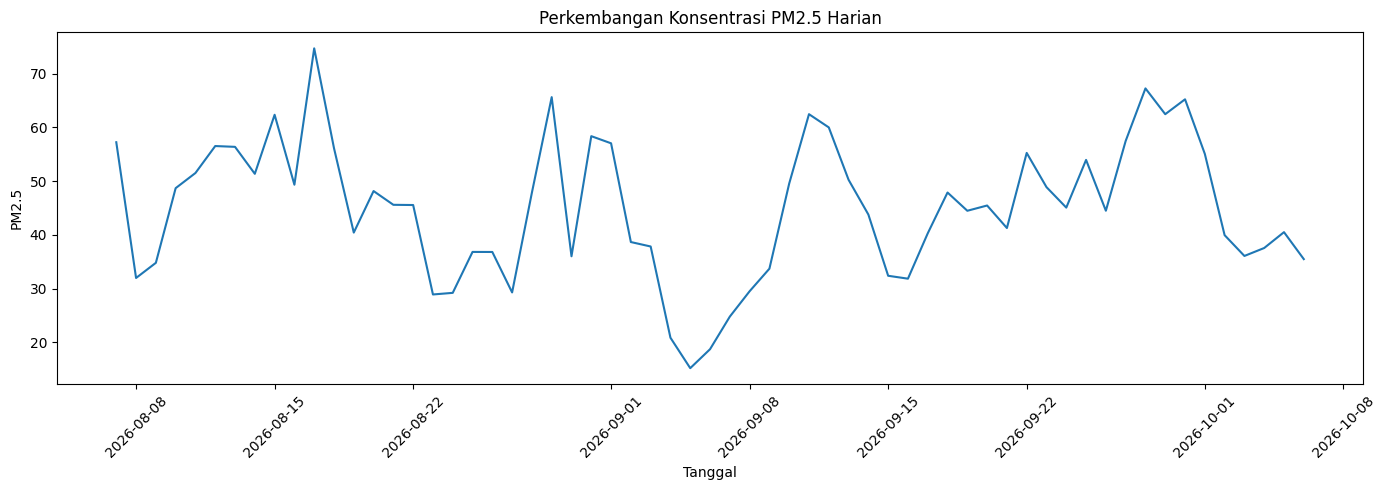

In [43]:
# ============================================================
# 5.2.1 PERKEMBANGAN PM2.5 HARIAN
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    integrated_data["tanggal"],
    integrated_data["PM2_5"]
)

plt.title("Perkembangan Konsentrasi PM2.5 Harian")
plt.xlabel("Tanggal")
plt.ylabel("PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5.2.2 Distribusi PM2.5

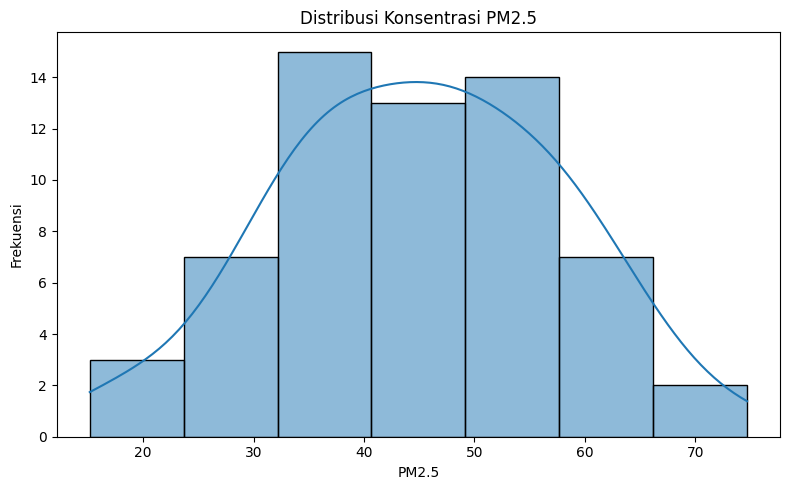

In [44]:
# ============================================================
# 5.2.2 DISTRIBUSI PM2.5
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    integrated_data["PM2_5"],
    kde=True
)

plt.title("Distribusi Konsentrasi PM2.5")
plt.xlabel("PM2.5")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# 5.2.3 Karakteristik Cuaca

In [45]:
# ============================================================
# 5.2.3 KARAKTERISTIK CUACA
# ============================================================

variabel_cuaca = [
    "temperature_mean",
    "humidity_mean",
    "precipitation_sum",
    "pressure_mean",
    "wind_speed_mean",
    "cloud_cover_mean"
]

display(
    integrated_data[variabel_cuaca].describe().round(2)
)

,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,cloud_cover_mean
count,61.00,61.00,61.00,61.00,61.00,61.00
mean,23.28,70.60,0.31,961.61,6.76,43.48
std,0.97,7.22,0.91,0.75,1.50,21.52
min,21.54,46.79,0.00,959.80,4.27,4.00
25%,22.47,66.33,0.00,961.02,5.71,26.33
50%,23.11,71.21,0.00,961.63,6.44,39.50
75%,23.98,76.12,0.30,962.14,7.71,61.12
max,25.38,81.79,6.50,963.12,10.24,88.79


In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    integrated_data["tanggal"],
    integrated_data["temperature_mean"]
)

plt.title("Perkembangan Temperatur Rata-rata Harian")
plt.xlabel("Tanggal")
plt.ylabel("Temperatur")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5.2.4 Karakteristik Hotspot

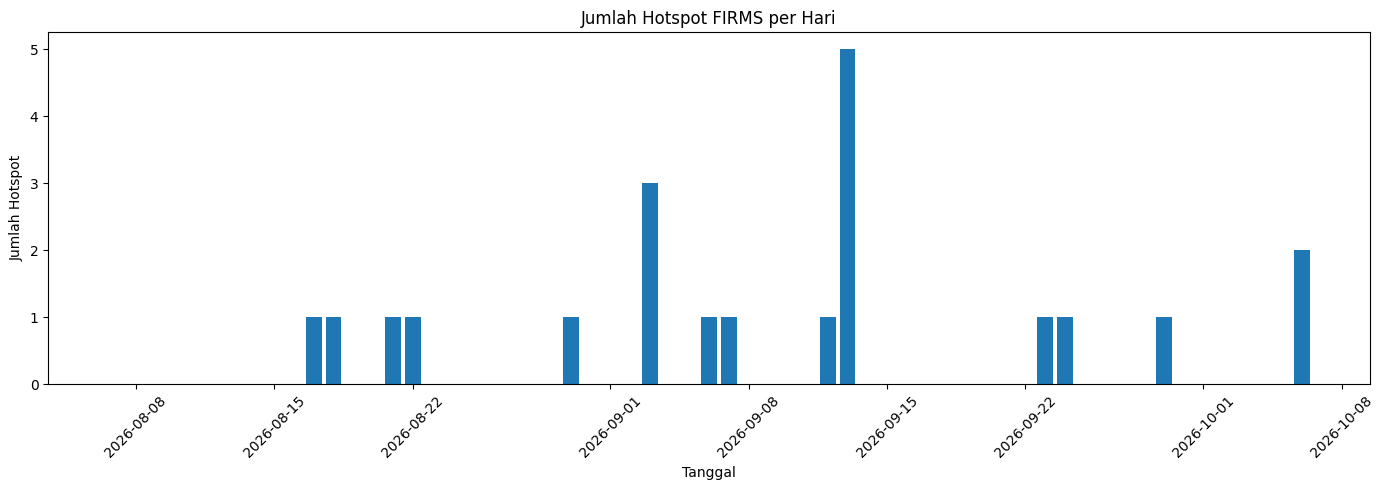

In [46]:
# ============================================================
# 5.2.4 KARAKTERISTIK HOTSPOT
# ============================================================

plt.figure(figsize=(14, 5))

plt.bar(
    integrated_data["tanggal"],
    integrated_data["hotspot_count"]
)

plt.title("Jumlah Hotspot FIRMS per Hari")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Hotspot")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5.3 Analisis Hubungan Cuaca dengan PM2.5

In [47]:
# ============================================================
# 5.3.1 KORELASI CUACA DENGAN PM2.5
# ============================================================

variabel_cuaca = [
    "temperature_mean",
    "humidity_mean",
    "precipitation_sum",
    "pressure_mean",
    "wind_speed_mean",
    "wind_direction_mean",
    "cloud_cover_mean"
]

korelasi_cuaca = integrated_data[
    ["PM2_5"] + variabel_cuaca
].corr()["PM2_5"].sort_values(ascending=False)

print("=== KORELASI CUACA DENGAN PM2.5 ===")
display(korelasi_cuaca.round(3))

=== KORELASI CUACA DENGAN PM2.5 ===


PM2_5                  1.000
temperature_mean       0.243
precipitation_sum      0.000
wind_direction_mean   -0.159
humidity_mean         -0.160
cloud_cover_mean      -0.268
pressure_mean         -0.375
wind_speed_mean       -0.537
Name: PM2_5, dtype: float64

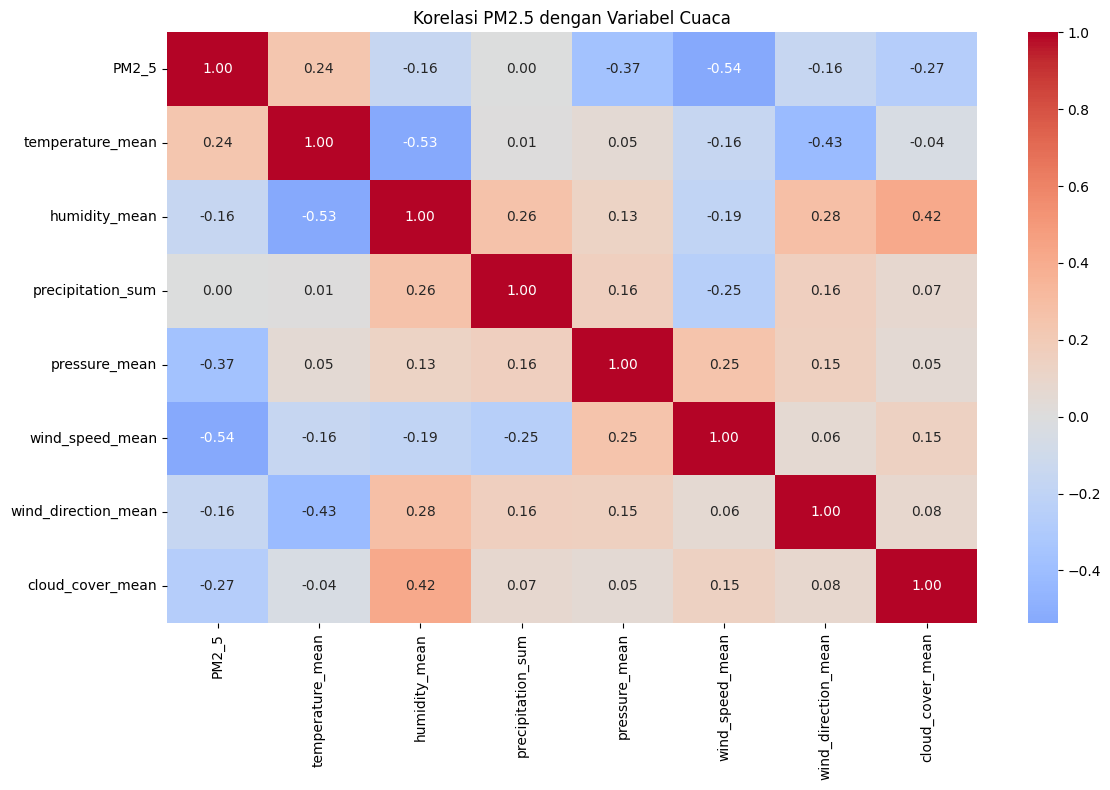

In [65]:
# ============================================================
# 5.3.2 HEATMAP KORELASI
# ============================================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    integrated_data[
        ["PM2_5"] + variabel_cuaca
    ].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Korelasi PM2.5 dengan Variabel Cuaca")
plt.tight_layout()
plt.show()

# 5.4 Analisis Hubungan Hotspot dengan PM2.5
Tahap ini digunakan untuk menjawab Research Question 3

In [48]:
# ============================================================
# 5.4.1 KORELASI HOTSPOT DENGAN PM2.5
# ============================================================

variabel_hotspot = [
    "hotspot_count",
    "total_frp",
    "max_frp"
]

korelasi_hotspot = integrated_data[
    ["PM2_5"] + variabel_hotspot
].corr()["PM2_5"].sort_values(ascending=False)

print("=== KORELASI HOTSPOT DENGAN PM2.5 ===")
display(korelasi_hotspot.round(3))

=== KORELASI HOTSPOT DENGAN PM2.5 ===


PM2_5            1.000
hotspot_count    0.011
max_frp         -0.037
total_frp       -0.050
Name: PM2_5, dtype: float64

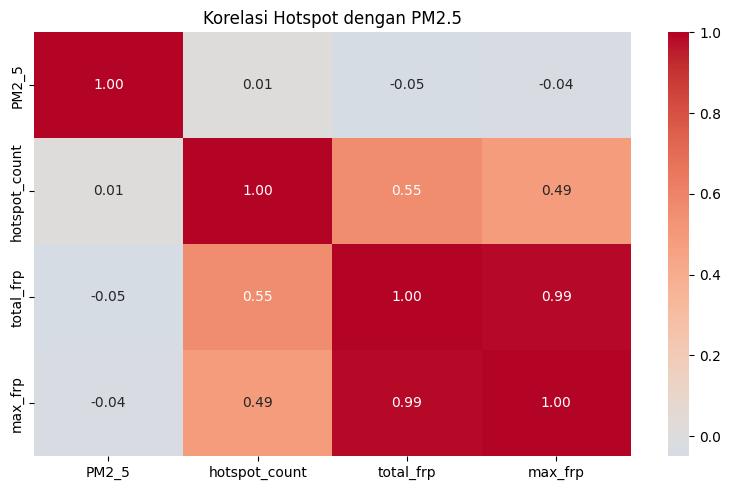

In [49]:
# ============================================================
# 5.4.2 HEATMAP KORELASI
# ============================================================

plt.figure(figsize=(8, 5))

sns.heatmap(
    integrated_data[
        ["PM2_5"] + variabel_hotspot
    ].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Korelasi Hotspot dengan PM2.5")
plt.tight_layout()
plt.show()

# PHASE 6 — DATA MODELING & MACHINE LEARNING

Pada tahap ini kita mulai memprediksi konsentrasi PM2.5 berdasarkan kondisi cuaca dan hotspot.
Model yang dibandingkan:
Linear Regression → melihat hubungan linear.
Random Forest Regression → menangkap hubungan yang lebih kompleks/nonlinear.

In [50]:
# ============================================================
# 6.1 PERSIAPAN DATA MODELING
# ============================================================

print("=== PERSIAPAN DATA MODELING ===")

# Fitur yang digunakan untuk prediksi
features = [
    "temperature_mean",
    "humidity_mean",
    "precipitation_sum",
    "pressure_mean",
    "wind_speed_mean",
    "wind_direction_mean",
    "cloud_cover_mean",
    "hotspot_count",
    "total_frp",
    "max_frp"
]

# Target
target = "PM2_5"

# Membuat dataset modeling
model_data = integrated_data[features + [target]].copy()

print("Jumlah data awal :", model_data.shape)

# Cek missing value
print("\n=== MISSING VALUES ===")
print(model_data.isnull().sum())

# Hapus baris yang masih memiliki missing value
model_data = model_data.dropna()

print("\nJumlah data setelah cleaning :", model_data.shape)

# Menentukan X dan y
X = model_data[features]
y = model_data[target]

print("\nJumlah fitur :", X.shape[1])
print("Jumlah target:", y.shape[0])

print("\n=== FITUR ===")
print(features)

print("\n=== TARGET ===")
print(target)

display(model_data.head())

=== PERSIAPAN DATA MODELING ===
Jumlah data awal : (61, 11)

=== MISSING VALUES ===
temperature_mean       0
humidity_mean          0
precipitation_sum      0
pressure_mean          0
wind_speed_mean        0
wind_direction_mean    0
cloud_cover_mean       0
hotspot_count          0
total_frp              0
max_frp                0
PM2_5                  0
dtype: int64

Jumlah data setelah cleaning : (61, 11)

Jumlah fitur : 10
Jumlah target: 61

=== FITUR ===
['temperature_mean', 'humidity_mean', 'precipitation_sum', 'pressure_mean', 'wind_speed_mean', 'wind_direction_mean', 'cloud_cover_mean', 'hotspot_count', 'total_frp', 'max_frp']

=== TARGET ===
PM2_5


,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp,PM2_5
0,22.30,68.38,0.0,960.33,6.49,193.58,20.67,0,0.0,0.0,57.23
1,22.25,74.12,0.0,961.52,8.43,198.00,43.46,0,0.0,0.0,31.96
2,21.54,78.33,0.0,960.08,6.38,184.54,61.12,0,0.0,0.0,34.78
3,21.85,77.83,0.0,959.80,6.78,180.33,47.62,0,0.0,0.0,48.68
4,21.64,76.12,0.0,960.38,5.71,200.21,26.33,0,0.0,0.0,51.50


In [51]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=== PEMBAGIAN DATA ===")
print("Data training :", X_train.shape[0])
print("Data testing  :", X_test.shape[0])

print("\nPersentase:")
print("Training :", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing  :", round(len(X_test) / len(X) * 100, 2), "%")

=== PEMBAGIAN DATA ===
Data training : 48
Data testing  : 13

Persentase:
Training : 78.69 %
Testing  : 21.31 %


# 6.2 Linear Regression
Model pertama adalah Linear Regression. Model ini digunakan untuk melihat apakah hubungan antara faktor cuaca + hotspot dengan PM2.5 dapat diprediksi dengan pola hubungan yang relatif linear.

In [52]:
# ============================================================
# 6.2.1 TRAINING MODEL
# ============================================================

from sklearn.linear_model import LinearRegression

print("=== LINEAR REGRESSION ===")

# Membuat model
lr_model = LinearRegression()

# Melatih model menggunakan data training
lr_model.fit(X_train, y_train)

# Melakukan prediksi pada data testing
y_pred_lr = lr_model.predict(X_test)

print("Model Linear Regression berhasil dilatih.")
print("Jumlah data testing :", len(X_test))
print("Jumlah hasil prediksi:", len(y_pred_lr))

=== LINEAR REGRESSION ===
Model Linear Regression berhasil dilatih.
Jumlah data testing : 13
Jumlah hasil prediksi: 13


In [53]:
# ============================================================
# 6.2.2 EVALUASI MODEL
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Menghitung MAE
mae_lr = mean_absolute_error(y_test, y_pred_lr)

# Menghitung MSE
mse_lr = mean_squared_error(y_test, y_pred_lr)

# Menghitung RMSE
rmse_lr = np.sqrt(mse_lr)

# Menghitung R²
r2_lr = r2_score(y_test, y_pred_lr)

print("=== HASIL EVALUASI LINEAR REGRESSION ===")
print(f"MAE  : {mae_lr:.3f}")
print(f"MSE  : {mse_lr:.3f}")
print(f"RMSE : {rmse_lr:.3f}")
print(f"R²   : {r2_lr:.3f}")

=== HASIL EVALUASI LINEAR REGRESSION ===
MAE  : 7.156
MSE  : 72.783
RMSE : 8.531
R²   : 0.410


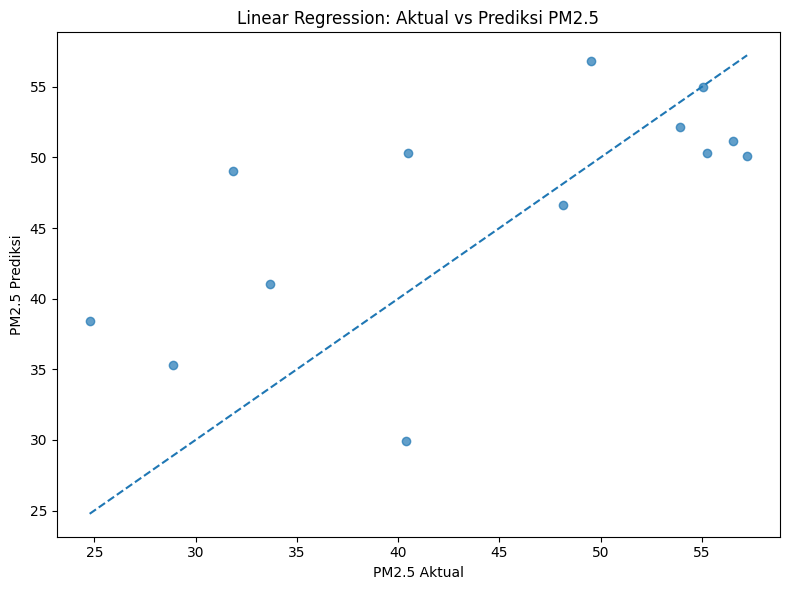

In [54]:
# ============================================================
# 6.2.3 AKTUAL VS PREDIKSI
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.7
)

# Garis prediksi sempurna
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Linear Regression: Aktual vs Prediksi PM2.5")
plt.xlabel("PM2.5 Aktual")
plt.ylabel("PM2.5 Prediksi")

plt.tight_layout()
plt.show()

# 6.3 Random Forest Regression

In [55]:
# ============================================================
# 6.3 RANDOM FOREST REGRESSION
# 6.3.1 TRAINING MODEL
# ============================================================

from sklearn.ensemble import RandomForestRegressor

print("=== RANDOM FOREST REGRESSION ===")

# Membuat model Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Melatih model menggunakan data training
rf_model.fit(X_train, y_train)

# Melakukan prediksi pada data testing
y_pred_rf = rf_model.predict(X_test)

print("Model Random Forest berhasil dilatih.")
print("Jumlah data testing :", len(X_test))
print("Jumlah hasil prediksi:", len(y_pred_rf))

=== RANDOM FOREST REGRESSION ===
Model Random Forest berhasil dilatih.
Jumlah data testing : 13
Jumlah hasil prediksi: 13


In [56]:
# ============================================================
# 6.3.2 EVALUASI MODEL
# ============================================================

# Menghitung MAE
mae_rf = mean_absolute_error(y_test, y_pred_rf)

# Menghitung MSE
mse_rf = mean_squared_error(y_test, y_pred_rf)

# Menghitung RMSE
rmse_rf = np.sqrt(mse_rf)

# Menghitung R²
r2_rf = r2_score(y_test, y_pred_rf)

print("=== HASIL EVALUASI RANDOM FOREST ===")
print(f"MAE  : {mae_rf:.3f}")
print(f"MSE  : {mse_rf:.3f}")
print(f"RMSE : {rmse_rf:.3f}")
print(f"R²   : {r2_rf:.3f}")

=== HASIL EVALUASI RANDOM FOREST ===
MAE  : 8.732
MSE  : 107.662
RMSE : 10.376
R²   : 0.127


In [57]:
# ============================================================
# 6.3.3 FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Fitur": features,
    "Importance": rf_model.feature_importances_
})

# Urutkan dari yang paling penting
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("=== FEATURE IMPORTANCE RANDOM FOREST ===")

display(
    feature_importance.round(4)
)

=== FEATURE IMPORTANCE RANDOM FOREST ===


,Fitur,Importance
0,wind_speed_mean,0.3530
1,pressure_mean,0.2901
2,wind_direction_mean,0.1103
3,temperature_mean,0.0840
4,cloud_cover_mean,0.0619
5,humidity_mean,0.0534
6,precipitation_sum,0.0238
7,max_frp,0.0106
8,total_frp,0.0101
9,hotspot_count,0.0028


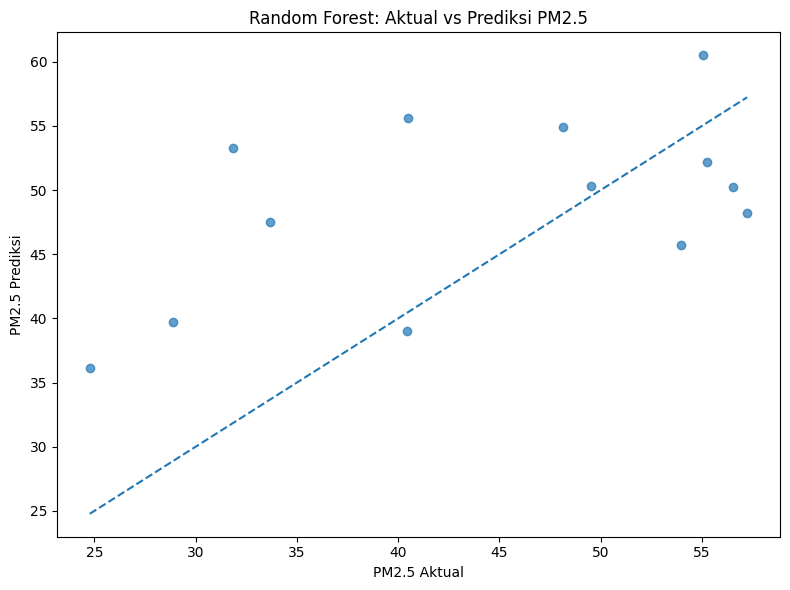

In [58]:
# ============================================================
# 6.3.4 AKTUAL VS PREDIKSI
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.7
)

# Garis prediksi sempurna
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Random Forest: Aktual vs Prediksi PM2.5")
plt.xlabel("PM2.5 Aktual")
plt.ylabel("PM2.5 Prediksi")

plt.tight_layout()
plt.show()

6.4 Perbandingan Model
Pada bagian ini kita membandingkan Linear Regression dan Random Forest Regression menggunakan empat metrik evaluasi.

In [59]:
# ============================================================
# 6.4.1 TABEL PERBANDINGAN
# ============================================================

hasil_model = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        mae_lr,
        mae_rf
    ],
    "MSE": [
        mse_lr,
        mse_rf
    ],
    "RMSE": [
        rmse_lr,
        rmse_rf
    ],
    "R2": [
        r2_lr,
        r2_rf
    ]
})

print("=== PERBANDINGAN KINERJA MODEL ===")

display(
    hasil_model.round(3)
)

=== PERBANDINGAN KINERJA MODEL ===


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7.156,72.783,8.531,0.410
1,Random Forest Regression,8.732,107.662,10.376,0.127


In [60]:
# ============================================================
# 6.4.2 MENENTUKAN MODEL TERBAIK
# ============================================================

print("=== MODEL TERBAIK ===")

# Model terbaik berdasarkan RMSE
model_terbaik_rmse = hasil_model.loc[
    hasil_model["RMSE"].idxmin(),
    "Model"
]

# Model terbaik berdasarkan R²
model_terbaik_r2 = hasil_model.loc[
    hasil_model["R2"].idxmax(),
    "Model"
]

print("Berdasarkan RMSE :", model_terbaik_rmse)
print("Berdasarkan R²   :", model_terbaik_r2)

=== MODEL TERBAIK ===
Berdasarkan RMSE : Linear Regression
Berdasarkan R²   : Linear Regression


In [61]:
print("Ukuran data:", integrated_data.shape)

print("\nKolom:")
print(integrated_data.columns.tolist())

print("\n5 data pertama:")
display(integrated_data.head())

Ukuran data: (61, 12)

Kolom:
['tanggal', 'PM2_5', 'temperature_mean', 'humidity_mean', 'precipitation_sum', 'pressure_mean', 'wind_speed_mean', 'wind_direction_mean', 'cloud_cover_mean', 'hotspot_count', 'total_frp', 'max_frp']

5 data pertama:


,tanggal,PM2_5,temperature_mean,humidity_mean,precipitation_sum,pressure_mean,wind_speed_mean,wind_direction_mean,cloud_cover_mean,hotspot_count,total_frp,max_frp
0,2026-08-07,57.23,22.30,68.38,0.0,960.33,6.49,193.58,20.67,0,0.0,0.0
1,2026-08-08,31.96,22.25,74.12,0.0,961.52,8.43,198.00,43.46,0,0.0,0.0
2,2026-08-09,34.78,21.54,78.33,0.0,960.08,6.38,184.54,61.12,0,0.0,0.0
3,2026-08-10,48.68,21.85,77.83,0.0,959.80,6.78,180.33,47.62,0,0.0,0.0
4,2026-08-11,51.50,21.64,76.12,0.0,960.38,5.71,200.21,26.33,0,0.0,0.0


In [62]:
import mysql.connector

db = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="admin",
    password="admin",
    database="airflow_malang"
)

cursor = db.cursor()

cursor.execute("DROP TABLE IF EXISTS integrated_data")

cursor.execute("""
CREATE TABLE integrated_data (
    id INT AUTO_INCREMENT PRIMARY KEY,
    tanggal DATE NOT NULL,
    PM2_5 FLOAT,
    temperature_mean FLOAT,
    humidity_mean FLOAT,
    precipitation_sum FLOAT,
    pressure_mean FLOAT,
    wind_speed_mean FLOAT,
    wind_direction_mean FLOAT,
    cloud_cover_mean FLOAT,
    hotspot_count INT,
    total_frp FLOAT,
    max_frp FLOAT,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
)
""")

db.commit()

print("Tabel integrated_data berhasil dibuat.")

Tabel integrated_data berhasil dibuat.


In [63]:
insert_query = """
INSERT INTO integrated_data (
    tanggal,
    PM2_5,
    temperature_mean,
    humidity_mean,
    precipitation_sum,
    pressure_mean,
    wind_speed_mean,
    wind_direction_mean,
    cloud_cover_mean,
    hotspot_count,
    total_frp,
    max_frp
)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

data_insert = []

for _, row in integrated_data.iterrows():
    data_insert.append((
        row["tanggal"],
        row["PM2_5"],
        row["temperature_mean"],
        row["humidity_mean"],
        row["precipitation_sum"],
        row["pressure_mean"],
        row["wind_speed_mean"],
        row["wind_direction_mean"],
        row["cloud_cover_mean"],
        row["hotspot_count"],
        row["total_frp"],
        row["max_frp"]
    ))

cursor.executemany(insert_query, data_insert)
db.commit()

print(f"{len(data_insert)} baris berhasil dimasukkan ke MySQL.")

61 baris berhasil dimasukkan ke MySQL.


In [64]:
cursor.execute("""
    SELECT *
    FROM integrated_data
    ORDER BY tanggal
    LIMIT 5
""")

for row in cursor.fetchall():
    print(row)

(1, datetime.date(2026, 8, 7), 57.23, 22.3, 68.38, 0.0, 960.33, 6.49, 193.58, 20.67, 0, 0.0, 0.0, datetime.datetime(2026, 10, 6, 19, 58, 3))
(2, datetime.date(2026, 8, 8), 31.96, 22.25, 74.12, 0.0, 961.52, 8.43, 198.0, 43.46, 0, 0.0, 0.0, datetime.datetime(2026, 10, 6, 19, 58, 3))
(3, datetime.date(2026, 8, 9), 34.78, 21.54, 78.33, 0.0, 960.08, 6.38, 184.54, 61.12, 0, 0.0, 0.0, datetime.datetime(2026, 10, 6, 19, 58, 3))
(4, datetime.date(2026, 8, 10), 48.68, 21.85, 77.83, 0.0, 959.8, 6.78, 180.33, 47.62, 0, 0.0, 0.0, datetime.datetime(2026, 10, 6, 19, 58, 3))
(5, datetime.date(2026, 8, 11), 51.5, 21.64, 76.12, 0.0, 960.38, 5.71, 200.21, 26.33, 0, 0.0, 0.0, datetime.datetime(2026, 10, 6, 19, 58, 3))
